In [1]:
import copy
import configparser
import json
import os
import time
 
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
 
matplotlib.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
 
from OptiLine import solvers, utils, opt_mintime
from OptiLine.KinematicProfs import (
    calc_vel_profile, calc_ax_profile, calc_t_profile,
)
from OptiLine.utils import (
    calc_splines, create_raceline, calc_head_curv_an, import_veh_dyn_info,
    seg_bounds, subsample_reftrack, raceline_from_alpha,
)

import fbga_py as fb

In [2]:
# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
MAPS_DIR    = "maps"
GGV_PATH    = os.path.join("input_files", "ggv.csv")
AX_MAX_PATH = os.path.join("input_files", "ax_max_machines.csv")
INI_PATH    = os.path.join("input_files", "racecar.ini")
FIG_DIR     = "paper_figs"
os.makedirs(FIG_DIR, exist_ok=True)
 
# ---------------------------------------------------------------------------
# Circuits
# OCP is expensive — run on BENCHMARK_CIRCUITS only (4 circuits).
# ---------------------------------------------------------------------------
BENCHMARK_CIRCUITS = {
    "BrandsHatch":     os.path.join(MAPS_DIR, "BrandsHatch",     "BrandsHatch_centerline.csv"),
    "Melbourne": os.path.join(MAPS_DIR, "Melbourne", "Melbourne_centerline.csv"),
    "Catalunya": os.path.join(MAPS_DIR, "Catalunya", "Catalunya_centerline.csv"),
    "Budapest":  os.path.join(MAPS_DIR, "Budapest",  "Budapest_centerline.csv"),
    "Sepang":  os.path.join(MAPS_DIR, "Sepang",  "Sepang_centerline.csv"),
}
 
# ---------------------------------------------------------------------------
# Vehicle parameters (matching racecar.ini)
# ---------------------------------------------------------------------------
VEH = dict(v_max=22.88, m_veh=1000.0, drag_coeff=0.75,
           kappa_bound=0.7, w_veh=1.0, fw=3, dyn_model_exp=1.5)

# ---------------------------------------------------------------------------
# Repeats for the stochastic solvers. ZORM and CMA-ES are unseeded, so every
# zeroth-order row below is the mean over N_REPEATS runs with its sample
# standard deviation. The deterministic rows (SP, MC, both OCPs) run once.
# ---------------------------------------------------------------------------
N_REPEATS = 3


def agg(vals):
    """(mean, sample std) of a list of scalars."""
    a = np.asarray(vals, dtype=float)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def median_idx(vals):
    """Index of the median run; used when one representative curve is needed."""
    a = np.asarray(vals, dtype=float)
    return int(np.argsort(a)[(a.size - 1) // 2])
 
# Shared ZO / CMA-ES hyperparameters
# min_s / max_s are set per-track inside seg_bounds()
HYP = dict(mu=0.0001, h=0.009,t = 1, MC=1, sigma=0.25,
           iterations_ZO=300, iterations_CMA=30, popsize=20, si=2)

# ---------------------------------------------------------------------------
# Load OCP parameters from racecar.ini (done once)
# ---------------------------------------------------------------------------
parser = configparser.ConfigParser()
if not parser.read(INI_PATH):
    raise FileNotFoundError(f"racecar.ini not found at {INI_PATH}")
 
OCP_PARS = {}
OCP_PARS["ggv_file"]               = json.loads(parser.get('GENERAL_OPTIONS', 'ggv_file'))
OCP_PARS["ax_max_machines_file"]   = json.loads(parser.get('GENERAL_OPTIONS', 'ax_max_machines_file'))
OCP_PARS["stepsize_opts"]          = json.loads(parser.get('GENERAL_OPTIONS', 'stepsize_opts'))
OCP_PARS["reg_smooth_opts"]        = json.loads(parser.get('GENERAL_OPTIONS', 'reg_smooth_opts'))
OCP_PARS["veh_params"]             = json.loads(parser.get('GENERAL_OPTIONS', 'veh_params'))
OCP_PARS["vel_calc_opts"]          = json.loads(parser.get('GENERAL_OPTIONS', 'vel_calc_opts'))
OCP_PARS["curv_calc_opts"]         = json.loads(parser.get('GENERAL_OPTIONS', 'curv_calc_opts'))
OCP_PARS["optim_opts"]             = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'optim_opts_mintime'))
OCP_PARS["vehicle_params_mintime"] = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'vehicle_params_mintime'))
OCP_PARS["tire_params_mintime"]    = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'tire_params_mintime'))
OCP_PARS["pwr_params_mintime"]     = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'pwr_params_mintime'))
OCP_PARS["vehicle_params_mintime"]["wheelbase"] = (
    OCP_PARS["vehicle_params_mintime"]["wheelbase_front"]
    + OCP_PARS["vehicle_params_mintime"]["wheelbase_rear"]
)
OCP_PARS["optim_opts"]["var_friction"] = None
OCP_PARS["optim_opts"]["warm_start"]   = False
 
# Fill safety limits from GGV
ggv_tmp, _ = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
if OCP_PARS["optim_opts"]["ax_pos_safe"] is None:
    OCP_PARS["optim_opts"]["ax_pos_safe"] = float(np.amin(ggv_tmp[:, 1]))
if OCP_PARS["optim_opts"]["ax_neg_safe"] is None:
    OCP_PARS["optim_opts"]["ax_neg_safe"] = float(-np.amin(ggv_tmp[:, 1]))
if OCP_PARS["optim_opts"]["ay_safe"] is None:
    OCP_PARS["optim_opts"]["ay_safe"]     = float(np.amin(ggv_tmp[:, 2]))


# Per-segment spline-length bounds for the bilevel optimiser: each interval is
# constrained to [lo * s_i, hi * s_i] of its OWN initial length (OptiLine >= 0.2.0).
# This replaces the previous global box [min_i s_i, k * max_i s_i], where a single
# short segment lowered the bound for every segment and could make the inner QP
# infeasible.
S_SCALE = (0.6, 1.5)  # (lo, hi) scaling factors for each segment's spline length

# Interior-point corridor constraints (OptiLine >= 0.2.5). The QPs constrain the
# raceline only at the reference-track nodes; the spline interpolated between them
# can bulge outside the track. Constraining a few interior points per segment
# removes that at a small extra QP cost. 0 restores the node-only behaviour of
# OptiLine <= 0.2.2. Passed explicitly everywhere so the setting is reproducible
# rather than inherited from the package default.
N_INTERP_CON = 2


In [ ]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------


SUBSAMPLE = 'arc'          # 'arc' or 'index'
# Measured convergence AND divergence (lap time [s], Solve_Succeeded unless noted):
#
#   circuit        600       800       1000      1700      3000
#   BrandsHatch     --      26.4426   26.4420     --      26.4405
#   Budapest        --      32.7887   32.7915     --      32.7908
#   Catalunya       --      33.2808   33.2806     --      33.2764
#   Melbourne     34.5193     --      34.6408   FAILED    FAILED
#
# The three circuits that converge everywhere agree to under 5 ms between 800 and
# 3000 cells, so a finer mesh buys nothing. MELBOURNE DIVERGES above ~1000 cells:
# IPOPT returns Error_In_Step_Computation and the solution is unusable, but at
# 1400-2500 cells it still returns a plausible-looking 35-38 s, so the failure is
# invisible unless solver_info['success'] is checked -- which run_pm now does by
# raising. At 3000 it degrades visibly (68.63 s, speed capped at 10.5 m/s against
# v_max 22.88).
#
# 1000 is therefore the finest mesh that solves everywhere, and it is 2.5x quicker
# than 3000 (~80 s against ~200 s per circuit).
PM_CELLS = 1000

# the bilevel optimiser here allows no compression and up to 1.8x stretching
SEG_LO, SEG_HI = 1.0, 1.8


def load_track(csv_path, step=4):
    data = np.loadtxt(csv_path, comments='#', delimiter=',')
    return subsample_reftrack(data[:, :4], step=step, mode=SUBSAMPLE)
 
 
def run_sp(reftrack):
    """Shortest path. Returns (laptime_s, raceline, elapsed_s)."""
    t0 = time.time()
    raceline, _, _, _, _, _, t = solvers.ShortestPath(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, w_veh=VEH['w_veh'], stepsize=HYP['si'],v_max=VEH['v_max'],
        plot=False, ggv_import_path=GGV_PATH,
        ax_max_machines_import_path=AX_MAX_PATH,
        dyn_model_exp=VEH['dyn_model_exp'],
    )
    return t[-1], raceline, time.time() - t0
 
 
def run_mc(reftrack):
    """Minimum curvature. Returns (laptime_s, raceline, elapsed_s)."""
    t0 = time.time()
    ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
    min_s, max_s, lengths = seg_bounds(reftrack, lo=SEG_LO, hi=SEG_HI)
    coeffs_x, coeffs_y, M, normvec = calc_splines(
        path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
        el_lengths=lengths, use_dist_scaling=True)
    alpha, _ = solvers.opt_min_curv(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, normvectors=normvec, A=M,
        kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
        print_debug=False, plot_debug=False, closed=True)
    raceline, kappa, el = raceline_from_alpha(
        reftrack, normvec, alpha, stepsize_interp=HYP['si'])
    vx = calc_vel_profile(ggv=ggv, ax_max_machines=ax_max,
                          v_max=VEH['v_max'], kappa=kappa,
                          el_lengths=el, closed=True,
                          filt_window=VEH['fw'],
                          dyn_model_exp=VEH['dyn_model_exp'],
                          drag_coeff=VEH['drag_coeff'],
                          m_veh=VEH['m_veh'])
    ax_p = calc_ax_profile(vx_profile=np.append(vx, vx[0]),
                           el_lengths=el, eq_length_output=False)
    t_prof = calc_t_profile(vx_profile=vx, ax_profile=ax_p, el_lengths=el)
    return t_prof[-1], raceline, time.time() - t0
 
 
def build_optct(reftrack, ggv_path=GGV_PATH):
    """
    Instantiate Opt_min_CurvTime with per-track min_s / max_s.
    min_s = lengths.min()        (no compression below point spacing)
    max_s = 2.0 * lengths.max()  (allow up to 2x stretching)
    """
    min_s, max_s, lengths = seg_bounds(reftrack, lo=SEG_LO, hi=SEG_HI)
    print(f"    [build_optct] seg lengths: min={lengths.min():.3f} m  "
          f"max={lengths.max():.3f} m  -> min_s={min_s:.3f}  max_s={max_s:.3f}")
    return solvers.Opt_min_CurvTime(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, center=reftrack,
        mu=HYP['mu'], h=HYP['h'],
        kapb=VEH['kappa_bound'], sfty=VEH['w_veh']/2,
        si=HYP['si'], vm=VEH['v_max'],
        m_veh=VEH['m_veh'], drag_coeff=VEH['drag_coeff'],
        t=HYP['t'], MC=HYP['MC'],
        s_scale=S_SCALE,
        sigma=HYP['sigma'],
        iterations_ZO=HYP['iterations_ZO'],
        iterations_CMA=HYP['iterations_CMA'],
        popsize=HYP['popsize'],
        ggv_import_path=ggv_path,
        ax_max_machines_import_path=AX_MAX_PATH,
        fw=VEH['fw'],
        dyn_model_exp=VEH['dyn_model_exp'],
    )
 
 
def run_pm(csv_path):
    """
    Point-mass minimum-lap-time OCP (MLTS-point-mass, via OptiLine.solvers).
    Returns (laptime_s, s, vx, raceline, elapsed_s).

    Unlike the other runners this takes the FULL centreline rather than the
    subsampled reference track. The sub-sampling is our optimisers' discretisation
    choice, not a property of the circuit, and at step=4 these circuits give
    max|kappa| * spacing of 1.0-2.2 against the 0.5 the solver wants -- at which
    point its reported lap time drifts up to 0.6 % from the path it actually
    returns (0.17 % on the full centreline). Runtime is the same either way,
    because the cost is set by the mesh rather than by the track table.

    Kept identical to the run_pm in Experiments.ipynb so the two notebooks report
    the same point-mass number for the same circuit.
    """
    t0 = time.time()
    ggv_t, axm_t = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
    full = subsample_reftrack(
        np.loadtxt(csv_path, comments='#', delimiter=',')[:, :4], step=1, mode='arc')
    pm = solvers.PointMassOCP(full, ggv_t,
                              w_veh=VEH['w_veh'], v_max=VEH['v_max'],
                              ax_max_machines=axm_t,
                              dyn_model_exp=VEH['dyn_model_exp'])
    pm.solve(mesh=max(0.05, pm.track_length / PM_CELLS))
    if not pm.solver_info['success']:
        raise RuntimeError(
            f"PointMassOCP did not converge ({pm.solver_info['status']}); "
            f"laptime {pm.laptime:.4f} s is not usable. Lower PM_CELLS for this "
            f"circuit -- see PM_CELLS for the measured per-circuit limits.")
    s_pm, vx_pm, _, _, _, rl_pm = pm.generate_kinProfs()
    return pm.laptime, s_pm, vx_pm, rl_pm, time.time() - t0


# ---------------------------------------------------------------------------
# Per-circuit OCP track discretisation.
#

OCP_STEPSIZE_REG = {
    "YasMarina": 1.5,   # 0.5 rejected by prep_track (crossed normals); 1.0 and
                      
}


def ocp_pars_for(name):
    """OCP_PARS with this circuit's stepsize_reg applied (deep copy, safe to mutate)."""
    pars = copy.deepcopy(OCP_PARS)
    if name in OCP_STEPSIZE_REG:
        pars["stepsize_opts"] = dict(pars["stepsize_opts"],
                                     stepsize_reg=OCP_STEPSIZE_REG[name])
    return pars


def run_ocp(reftrack, name=None):
    """
    Minimum-time OCP via opt_mintime.
    Returns (laptime_s, raceline, elapsed_s).
    Timing covers prep_track + opt_mintime solve.
    """
    t0 = time.time()
    pars = ocp_pars_for(name)
 
    reftrack_interp, normvec_interp, a_interp, cx_interp, cy_interp = \
        utils.prep_track(
            reftrack_imp=reftrack,
            reg_smooth_opts=pars["reg_smooth_opts"],
            stepsize_opts=pars["stepsize_opts"],
            debug=False,
            min_width=None,
        )
 
    alpha_opt, v_opt, raceline_opt, _, _, _, s_opt, laptime = \
        opt_mintime.opt_mintime(
            reftrack=reftrack_interp,
            coeffs_x=cx_interp,
            coeffs_y=cy_interp,
            normvectors=normvec_interp,
            pars=pars,
            print_debug=False,
            plot_=False,
        )
 
    return laptime, raceline_opt, time.time() - t0

Below I imported fbga directly and calculate the velocity profile using the embedded forward-backward solver of optiline and fbga for comparison.

Circuit: Sepang   points/lap: 480   lap length: 479.8 m
  OptiLine FB : v[min/mean/max] =  3.84 / 13.66 / 22.88 m/s   lap = 42.237 s
  FBGA  Fb2d  : v[min/mean/max] =  3.84 / 13.64 / 22.88 m/s   lap = 42.315 s
  velocity diff (FBGA - OptiLine): mean|.| = 0.100   max|.| = 0.871 m/s   lap dt = +0.078 s


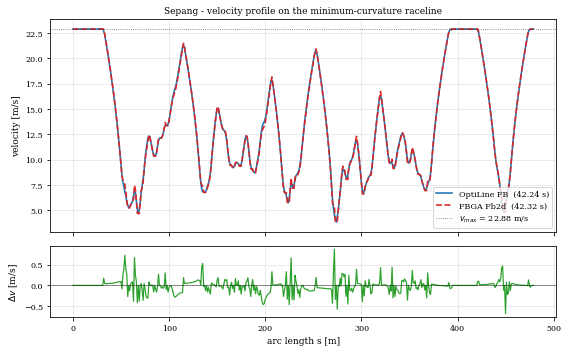

In [4]:
# ===========================================================================
# Fb2D example - compare velocity profiles on ONE optimised raceline
#
#   Solver A : OptiLine forward-backward  (calc_vel_profile, TUM-style)
#   Solver B : FBGA  Fb2d  (github.com/DRIVEWISE/FBGA, pip: fbga-py)
#
# Both solvers are fed the SAME optimised raceline (minimum-curvature line
# on the same track) and the SAME vehicle parameters, so the only thing that
# differs is the velocity-profile algorithm itself.
# ===========================================================================
import fbga_py as fb

# ---------------------------------------------------------------------------
# 0. Shared parameters (identical for both solvers)
# ---------------------------------------------------------------------------
CIRCUIT   = "Sepang"  # one of BENCHMARK_CIRCUITS
ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)   # ggv: [v, ax_max, ay_max]

DYN   = VEH['dyn_model_exp']     # vehicle-dynamics-model exponent (1=diamond, 2=ellipse)
DRAG  = VEH['drag_coeff']        # 0.5 * c_w * A * rho
M_VEH = VEH['m_veh']
VMAX  = VEH['v_max']
MU    = 1.0                      # friction scaling (calc_vel_profile default when mu=None)

# ---------------------------------------------------------------------------
# 1. Optimise ONE raceline (minimum curvature) and get kappa / el_lengths
#    (same procedure as run_mc)
# ---------------------------------------------------------------------------
reftrack = load_track(BENCHMARK_CIRCUITS[CIRCUIT])
_, _, lengths = seg_bounds(reftrack)

cx0, cy0, M, normvec = calc_splines(
    path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
    el_lengths=lengths, use_dist_scaling=True)
alpha, _ = solvers.opt_min_curv(
        n_interp_con=N_INTERP_CON,
    reftrack=reftrack, normvectors=normvec, A=M,
    kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
    print_debug=False, plot_debug=False, closed=True)
raceline, _, cx, cy, sind, tv, _, _, el = create_raceline(
    refline=reftrack[:, :2], normvectors=normvec,
    alpha=alpha, stepsize_interp=1)
_, kappa = calc_head_curv_an(coeffs_x=cx, coeffs_y=cy, ind_spls=sind, t_spls=tv)

N     = kappa.size
L     = float(el.sum())                                 # lap length [m]
s_lap = np.concatenate(([0.0], np.cumsum(el)[:-1]))     # arc length of each point [m]

# ---------------------------------------------------------------------------
# 2. Solver A - OptiLine forward-backward velocity profile (closed)
# ---------------------------------------------------------------------------
vx_ol = calc_vel_profile(
    ggv=ggv, ax_max_machines=ax_max, v_max=VMAX,
    kappa=kappa, el_lengths=el, closed=True,
    filt_window=VEH['fw'], dyn_model_exp=DYN,
    drag_coeff=DRAG, m_veh=M_VEH)

# ---------------------------------------------------------------------------
# 3. Solver B - FBGA Fb2d
#    Build the g-g bounds so they reproduce EXACTLY the accel model used
#    inside OptiLine's calc_ax_poss:
#        ax_max_tire(v) = mu * interp(v, ggv[:,0], ggv[:,1])
#        ay_max_tire(v) = mu * interp(v, ggv[:,0], ggv[:,2])
#        ax_avail(ay,v) = ax_max_tire * (1 - (|ay|/ay_max_tire)^DYN)^(1/DYN)
#        accel : min(ax_avail, ax_machine) - drag*v^2/m     (drag reduces accel)
#        brake : -ax_avail                - drag*v^2/m     (drag increases brake)
#        + hard top-speed cap at VMAX
#    FBGA is an OPEN solver, so we tile the raceline over 3 laps and keep the
#    middle lap - the same trick OptiLine uses internally to get a closed,
#    periodic profile.
# ---------------------------------------------------------------------------
def _ax_max_tire(v): return MU * np.interp(v, ggv[:, 0], ggv[:, 1])
def _ay_max_tire(v): return MU * np.interp(v, ggv[:, 0], ggv[:, 2])
def _ax_machine(v):  return np.interp(v, ax_max[:, 0], ax_max[:, 1])

def _ax_avail_tire(ay, v):
    ay_max = _ay_max_tire(v)
    radicand = 1.0 - (min(abs(ay) / ay_max, 1.0)) ** DYN
    return _ax_max_tire(v) * radicand ** (1.0 / DYN) if radicand > 0.0 else 0.0

def gg_upper(ay, v):                       # max longitudinal accel (drive)
    ax = min(_ax_avail_tire(ay, v), _ax_machine(v)) - v * v * DRAG / M_VEH
    return min(ax, 0.0) if v >= VMAX else ax     # top-speed cap

def gg_lower(ay, v):                       # min longitudinal accel (brake)
    return -_ax_avail_tire(ay, v) - v * v * DRAG / M_VEH

gg_range = fb.GgRangeMaxMin()
gg_range.max = lambda v:  _ay_max_tire(v)
gg_range.min = lambda v: -_ay_max_tire(v)

fb2d = fb.Fb2d(gg_upper, gg_lower, gg_range)

SS3 = np.concatenate([s_lap, s_lap + L, s_lap + 2 * L]).tolist()
KK3 = np.concatenate([kappa, kappa, kappa]).tolist()
fb2d.compute(SS3, KK3, float(VMAX), float(VMAX))   # v0 = vfmax = VMAX
_, _, VX3 = fb2d.evaluate(SS3)
vx_fb = np.asarray(VX3)[N:2 * N]                    # middle lap -> closed profile

# ---------------------------------------------------------------------------
# 4. Lap times (identical trapezoidal integrator for a fair comparison)
# ---------------------------------------------------------------------------
def lap_time(vx, el):
    v_seg = 0.5 * (vx + np.roll(vx, -1))           # closed: last -> first
    return float(np.sum(el / v_seg))

t_ol, t_fb = lap_time(vx_ol, el), lap_time(vx_fb, el)
diff = vx_fb - vx_ol

print(f"Circuit: {CIRCUIT}   points/lap: {N}   lap length: {L:.1f} m")
print(f"  OptiLine FB : v[min/mean/max] = "
      f"{vx_ol.min():5.2f} / {vx_ol.mean():5.2f} / {vx_ol.max():5.2f} m/s   "
      f"lap = {t_ol:6.3f} s")
print(f"  FBGA  Fb2d  : v[min/mean/max] = "
      f"{vx_fb.min():5.2f} / {vx_fb.mean():5.2f} / {vx_fb.max():5.2f} m/s   "
      f"lap = {t_fb:6.3f} s")
print(f"  velocity diff (FBGA - OptiLine): "
      f"mean|.| = {np.mean(np.abs(diff)):.3f}   max|.| = {np.max(np.abs(diff)):.3f} m/s   "
      f"lap dt = {t_fb - t_ol:+.3f} s")

# ---------------------------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------------------------
fig, (axv, axd) = plt.subplots(2, 1, figsize=(8, 5), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

axv.plot(s_lap, vx_ol, '-',  color='tab:blue', lw=1.6, label=f'OptiLine FB  ({t_ol:.2f} s)')
axv.plot(s_lap, vx_fb, '--', color='tab:red',  lw=1.6, label=f'FBGA Fb2d  ({t_fb:.2f} s)')
axv.axhline(VMAX, color='k', ls=':', lw=0.8, alpha=0.6, label=f'$v_{{max}}$ = {VMAX} m/s')
axv.set_ylabel('velocity [m/s]')
axv.set_title(f'{CIRCUIT} - velocity profile on the minimum-curvature raceline')
axv.grid(True, alpha=0.3)
axv.legend(loc='lower right')

axd.plot(s_lap, diff, color='tab:green', lw=1.2)
axd.axhline(0, color='k', lw=0.7, alpha=0.6)
axd.set_ylabel(r'$\Delta v$ [m/s]')
axd.set_xlabel('arc length s [m]')
axd.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'fb2d_vs_optiline_{CIRCUIT}.png'))
plt.show()


Below I repeated the same example but just with the integrated fbga in optiline. So from here, no direct import of fbga is needed.

Circuit: Sepang   points/lap: 480   lap length: 479.8 m
  OptiLine FB            : v[min/mean/max] =  3.84 / 13.66 / 22.88 m/s   lap = 42.237 s
  FBGA fb2d (integrated) : v[min/mean/max] =  3.84 / 13.64 / 22.88 m/s   lap = 42.315 s
  velocity diff (FBGA - OptiLine): mean|.| = 0.100   max|.| = 0.871 m/s   lap dt = +0.078 s


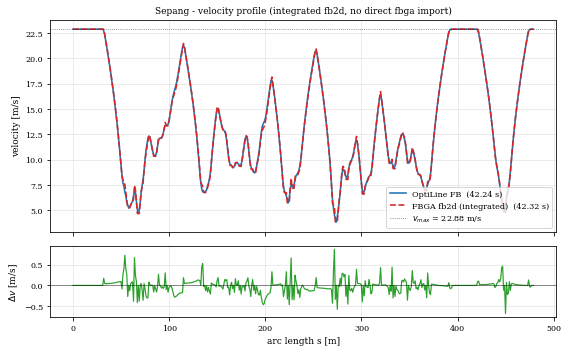

In [5]:
# ===========================================================================
# Fb2D example (INTEGRATED) - same comparison as above, but the FBGA Fb2d
# velocity profile is now produced by OptiLine's built-in calc_vel_profile_fb2d.
# There is NO direct `import fbga_py` here.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d, calc_vel_profile_solver

# ---------------------------------------------------------------------------
# 0. Shared parameters (identical for both solvers)
# ---------------------------------------------------------------------------

ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)   # ggv: [v, ax_max, ay_max]

DYN   = VEH['dyn_model_exp']     # vehicle-dynamics-model exponent (1=diamond, 2=ellipse)
DRAG  = VEH['drag_coeff']        # 0.5 * c_w * A * rho
M_VEH = VEH['m_veh']
VMAX  = VEH['v_max']

# ---------------------------------------------------------------------------
# 1. Optimise ONE raceline (minimum curvature) and get kappa / el_lengths
# ---------------------------------------------------------------------------
reftrack = load_track(BENCHMARK_CIRCUITS[CIRCUIT])
_, _, lengths = seg_bounds(reftrack)

cx0, cy0, M, normvec = calc_splines(
    path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
    el_lengths=lengths, use_dist_scaling=True)
alpha, _ = solvers.opt_min_curv(
        n_interp_con=N_INTERP_CON,
    reftrack=reftrack, normvectors=normvec, A=M,
    kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
    print_debug=False, plot_debug=False, closed=True)
raceline, _, cx, cy, sind, tv, _, _, el = create_raceline(
    refline=reftrack[:, :2], normvectors=normvec,
    alpha=alpha, stepsize_interp=1)
_, kappa = calc_head_curv_an(coeffs_x=cx, coeffs_y=cy, ind_spls=sind, t_spls=tv)

N     = kappa.size
L     = float(el.sum())                                 # lap length [m]
s_lap = np.concatenate(([0.0], np.cumsum(el)[:-1]))     # arc length of each point [m]

# ---------------------------------------------------------------------------
# 2. Solver A - OptiLine forward-backward velocity profile (closed)
# ---------------------------------------------------------------------------
vx_ol = calc_vel_profile(
    ggv=ggv, ax_max_machines=ax_max, v_max=VMAX,
    kappa=kappa, el_lengths=el, closed=True,
    filt_window=VEH['fw'], dyn_model_exp=DYN,
    drag_coeff=DRAG, m_veh=M_VEH)

# ---------------------------------------------------------------------------
# 3. Solver B - FBGA Fb2d via OptiLine's integrated calculator.
#    Same ggv / parameters as Solver A; calc_vel_profile_fb2d internally
# ---------------------------------------------------------------------------
vx_fb, ax_fb = calc_vel_profile_fb2d(
    ggv=ggv, ax_max_machines=ax_max, v_max=VMAX,
    kappa=kappa, el_lengths=el, closed=True,
    dyn_model_exp=DYN, drag_coeff=DRAG, m_veh=M_VEH,
    return_accel=True)


# ---------------------------------------------------------------------------
# 4. Lap times (identical trapezoidal integrator for a fair comparison)
# ---------------------------------------------------------------------------
def lap_time(vx, el):
    v_seg = 0.5 * (vx + np.roll(vx, -1))           # closed: last -> first
    return float(np.sum(el / v_seg))

t_ol, t_fb = lap_time(vx_ol, el), lap_time(vx_fb, el)
diff = vx_fb - vx_ol

print(f"Circuit: {CIRCUIT}   points/lap: {N}   lap length: {L:.1f} m")
print(f"  OptiLine FB            : v[min/mean/max] = "
      f"{vx_ol.min():5.2f} / {vx_ol.mean():5.2f} / {vx_ol.max():5.2f} m/s   lap = {t_ol:6.3f} s")
print(f"  FBGA fb2d (integrated) : v[min/mean/max] = "
      f"{vx_fb.min():5.2f} / {vx_fb.mean():5.2f} / {vx_fb.max():5.2f} m/s   lap = {t_fb:6.3f} s")
print(f"  velocity diff (FBGA - OptiLine): "
      f"mean|.| = {np.mean(np.abs(diff)):.3f}   max|.| = {np.max(np.abs(diff)):.3f} m/s   "
      f"lap dt = {t_fb - t_ol:+.3f} s")

# ---------------------------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------------------------
fig, (axv, axd) = plt.subplots(2, 1, figsize=(8, 5), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

axv.plot(s_lap, vx_ol, '-',  color='tab:blue', lw=1.6, label=f'OptiLine FB  ({t_ol:.2f} s)')
axv.plot(s_lap, vx_fb, '--', color='tab:red',  lw=1.6, label=f'FBGA fb2d (integrated)  ({t_fb:.2f} s)')
axv.axhline(VMAX, color='k', ls=':', lw=0.8, alpha=0.6, label=f'$v_{{max}}$ = {VMAX} m/s')
axv.set_ylabel('velocity [m/s]')
axv.set_title(f'{CIRCUIT} - velocity profile (integrated fb2d, no direct fbga import)')
axv.grid(True, alpha=0.3)
axv.legend(loc='lower right')

axd.plot(s_lap, diff, color='tab:green', lw=1.2)
axd.axhline(0, color='k', lw=0.7, alpha=0.6)
axd.set_ylabel(r'$\Delta v$ [m/s]')
axd.set_xlabel('arc length s [m]')
axd.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'fb2d_integrated_vs_optiline_{CIRCUIT}.png'))
plt.show()


Below is a general benchmark on the **Budapest** map. For every method we compute the lap time and velocity profile: shortest path, minimum curvature, minimum-time OCP, and the bilevel (`Opt_min_CurvTime`) and blackbox (`Blackbox_raceline`) optimisers run with **both** velocity-profile calculators (`vel_solver='fb'` and `'fb2d'`) using ZORM and CMA-ES. All `calc_vel_profile`-based profiles use the same `maps/ggv.csv` as the previous example.

In [ ]:
# ===========================================================================
# General benchmark on Sepang: lap time + velocity profile for every method.
# The bilevel and blackbox optimisers are each run with BOTH velocity-profile
# calculators (vel_solver='fb' and 'fb2d') under ZORM and CMA-ES.
# All calc_vel_profile-based profiles use the SAME ggv (input_files/ggv.csv).
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_solver, calc_vel_profile_fb2d


reftrack = load_track(BENCHMARK_CIRCUITS[CIRCUIT])
ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)

# --- iteration budgets (increase for higher-quality optima) ---------------
BILEVEL = dict(iterations_ZO=180, iterations_CMA=18, popsize=20, sigma=0.1, h = 5e-3)
BBA     = dict(mu=1e-5, h=3e-4, t=12, iters_ZO=2500, iters_CMA=600,
               popsize=12, sigma=1e-2, n_jobs=12)   # bump n_jobs to parallelise blackbox



In [7]:
# results collector ---------------------------------------------------------
results = []
def add(label, group, laptime, s, vx, sec, hist=None, sd=0.0,
        prof_runs=None, hist_runs=None):
    """Record one method. `sd` is the spread over repeats (0 when deterministic);
    `prof_runs` and `hist_runs` keep every run so the figures can show a band."""
    s  = np.asarray(s,  float)
    vx = np.asarray(vx, float)
    n  = min(len(s), len(vx))                       # align (some solvers return s of len n+1)
    s, vx = s[:n], vx[:n]
    results.append(dict(label=label, group=group, laptime=float(laptime),
                        sd=float(sd), s=s, vx=vx, sec=sec,
                        prof_runs=prof_runs, hist_runs=hist_runs,
                        hist=None if hist is None else np.asarray(hist, float)))
    _spread = "" if sd == 0.0 else f" +- {sd:5.3f}"
    print(f"  {label:22s}  lap = {float(laptime):7.3f}{_spread} s   ({sec:5.1f} s)")

print(f"=== Sepang benchmark ({reftrack.shape[0]} reference points) ===")

=== Sepang benchmark (277 reference points) ===


In [8]:
# ===========================================================================
# Per-evaluation cost of the two velocity solvers (fb vs fb2d)
#   - velocity profile alone
#   - one bilevel  cost eval  f_t()            (dominated by the min-curvature QP)
#   - one blackbox cost eval  _laptime_cost()  (dominated by the profile, no QP)
# It does NOT touch `results`.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d

def _timeit(fn, n=15):
    fn()                                        # warm-up
    t0 = time.time()
    for _ in range(n):
        fn()
    return (time.time() - t0) / n * 1e3         # ms per call

# representative minimum-curvature raceline -> kappa / el_lengths
_mn, _mx, _lengths = seg_bounds(reftrack)
_, _, _M, _nv = calc_splines(path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
                             el_lengths=_lengths, use_dist_scaling=True)
_alpha, _ = solvers.opt_min_curv(n_interp_con=N_INTERP_CON,
        reftrack=reftrack, normvectors=_nv, A=_M,
                                 kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
                                 print_debug=False, plot_debug=False, closed=True)
_, _, _cx, _cy, _si, _tv, _, _, _el = create_raceline(
    refline=reftrack[:, :2], normvectors=_nv, alpha=_alpha, stepsize_interp=HYP['si'])
_, _kappa = calc_head_curv_an(coeffs_x=_cx, coeffs_y=_cy, ind_spls=_si, t_spls=_tv)
_vpkw = dict(ggv=ggv, ax_max_machines=ax_max, v_max=VEH['v_max'], kappa=_kappa,
             el_lengths=_el, closed=True, dyn_model_exp=VEH['dyn_model_exp'],
             drag_coeff=VEH['drag_coeff'], m_veh=VEH['m_veh'])

# (a) velocity profile only
vp_fb   = _timeit(lambda: calc_vel_profile(filt_window=VEH['fw'], **_vpkw))
vp_fb2d = _timeit(lambda: calc_vel_profile_fb2d(**_vpkw))

# (b) one bilevel cost evaluation f_t()  (spline fit + min-curvature QP + profile)
def _mk_ct(vel):
    return solvers.Opt_min_CurvTime(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, center=reftrack, mu=HYP['mu'], h=HYP['h'],
        kapb=VEH['kappa_bound'], sfty=VEH['w_veh']/2, si=HYP['si'], vm=VEH['v_max'],
        m_veh=VEH['m_veh'], drag_coeff=VEH['drag_coeff'], t=HYP['t'], MC=HYP['MC'],
        s_scale=S_SCALE, sigma=HYP['sigma'],
        iterations_ZO=1, iterations_CMA=1, popsize=4,
        ggv_import_path=GGV_PATH, ax_max_machines_import_path=AX_MAX_PATH,
        fw=VEH['fw'], vel_solver=vel, dyn_model_exp=VEH['dyn_model_exp'])
_ct_fb, _ct_fb2d = _mk_ct('fb'), _mk_ct('fb2d')
ft_fb   = _timeit(lambda: _ct_fb.f_t(_lengths),   n=8)
ft_fb2d = _timeit(lambda: _ct_fb2d.f_t(_lengths), n=8)

# (c) one blackbox cost evaluation _laptime_cost()  (raceline build + profile, NO QP)
def _mk_bb(vel):
    return solvers.Blackbox_raceline(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, ggv=ggv, ax_max_machines=ax_max, sfty=VEH['w_veh']/2,
        v_max=VEH['v_max'], si=HYP['si'], fw=VEH['fw'], m_veh=VEH['m_veh'],
        drag_coeff=VEH['drag_coeff'], dyn_model_exp=VEH['dyn_model_exp'],
        init='mincurv', kappa_bound=VEH['kappa_bound'], n_jobs=1, vel_solver=vel)
_bb_fb, _bb_fb2d = _mk_bb('fb'), _mk_bb('fb2d')
_a0 = _bb_fb.alpha_0.copy()
lc_fb   = _timeit(lambda: _bb_fb._laptime_cost(_a0),   n=10)
lc_fb2d = _timeit(lambda: _bb_fb2d._laptime_cost(_a0), n=10)

# --- table -----------------------------------------------------------------
print("=" * 60)
print(f"  Per-evaluation cost: fb vs fb2d   ({CIRCUIT})")
print("=" * 60)
print(f"  {'stage':<26}{'fb':>9}{'fb2d':>10}{'ratio':>8}")
print("  " + "-" * 54)
def _row(name, a, b):
    print(f"  {name:<26}{a:>7.1f}ms{b:>8.1f}ms{b/a:>6.1f}x")
_row("velocity profile alone",   vp_fb, vp_fb2d)
_row("bilevel  f_t() eval",      ft_fb, ft_fb2d)
_row("blackbox _laptime_cost()", lc_fb, lc_fb2d)
print("=" * 60)
print(f"  velocity-profile share of one eval (fb):  "
      f"bilevel {vp_fb/ft_fb*100:.0f}%   blackbox {vp_fb/lc_fb*100:.0f}%")
print("  -> fb2d's heavy profile cost is hidden behind the QP in the bilevel")
print("     eval, but dominates the QP-free blackbox eval.")


  Per-evaluation cost: fb vs fb2d   (Sepang)
  stage                            fb      fb2d   ratio
  ------------------------------------------------------
  velocity profile alone        5.1ms    20.6ms   4.1x
  bilevel  f_t() eval         270.1ms   281.0ms   1.0x
  blackbox _laptime_cost()      6.4ms    25.4ms   4.0x
  velocity-profile share of one eval (fb):  bilevel 2%   blackbox 80%
  -> fb2d's heavy profile cost is hidden behind the QP in the bilevel
     eval, but dominates the QP-free blackbox eval.


In [9]:
# 1) Shortest path -----------------------------------------------------------
t0 = time.time()
_, _, s_sp, vx_sp, _, _, t_sp = solvers.ShortestPath(
        n_interp_con=N_INTERP_CON,
    reftrack=reftrack, w_veh=VEH['w_veh'], stepsize=HYP['si'], v_max=VEH['v_max'],
    plot=False, ggv_import_path=GGV_PATH, ax_max_machines_import_path=AX_MAX_PATH,
    dyn_model_exp=VEH['dyn_model_exp'])
add("Shortest path", "reference", t_sp[-1], s_sp, vx_sp, time.time()-t0)

# 2) Minimum curvature -------------------------------------------------------
t0 = time.time()
mn, mx, lengths = seg_bounds(reftrack)
_, _, Mmc, nv = calc_splines(path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
                             el_lengths=lengths, use_dist_scaling=True)
alpha_mc, _ = solvers.opt_min_curv(n_interp_con=N_INTERP_CON,
        reftrack=reftrack, normvectors=nv, A=Mmc,
                                   kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
                                   print_debug=False, plot_debug=False, closed=True)
_, _, cxm, cym, sim, tvm, _, _, el_mc = create_raceline(
    refline=reftrack[:, :2], normvectors=nv, alpha=alpha_mc, stepsize_interp=HYP['si'])
_, kappa_mc = calc_head_curv_an(coeffs_x=cxm, coeffs_y=cym, ind_spls=sim, t_spls=tvm)
vx_mc = calc_vel_profile(ggv=ggv, ax_max_machines=ax_max, v_max=VEH['v_max'],
                         kappa=kappa_mc, el_lengths=el_mc, closed=True, filt_window=VEH['fw'],
                         dyn_model_exp=VEH['dyn_model_exp'], drag_coeff=VEH['drag_coeff'], m_veh=VEH['m_veh'])
axp_mc = calc_ax_profile(vx_profile=np.append(vx_mc, vx_mc[0]), el_lengths=el_mc, eq_length_output=False)
t_mc   = calc_t_profile(vx_profile=vx_mc, ax_profile=axp_mc, el_lengths=el_mc)
s_mc   = np.concatenate(([0.0], np.cumsum(el_mc)[:-1]))
add("Minimum curvature", "reference", t_mc[-1], s_mc, vx_mc, time.time()-t0)





  Shortest path           lap =  43.682 s   (  0.4 s)
  Minimum curvature       lap =  42.486 s   (  0.9 s)


In [10]:
# 3) Minimum-time OCP
try:
    t0 = time.time()
    pars = ocp_pars_for(CIRCUIT)
    rti, nvi, ai, cxi, cyi = utils.prep_track(
        reftrack_imp=reftrack, reg_smooth_opts=pars["reg_smooth_opts"],
        stepsize_opts=pars["stepsize_opts"], debug=False, min_width=None)
    _, v_opt, _, _, _, _, s_opt, lap_ocp = opt_mintime.opt_mintime(
        reftrack=rti, coeffs_x=cxi, coeffs_y=cyi, normvectors=nvi,
        pars=pars, print_debug=False, plot_=False)
    add("Min-time OCP", "reference", lap_ocp, s_opt, v_opt, time.time()-t0)
except Exception as e:
    print("  Min-time OCP skipped:", type(e).__name__, str(e)[:100])

-0.117405 0.122595 1.11298 1.0

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:   179090
Number of nonzeros in inequality constraint Jacobian.:    58064
Number of nonzeros in Lagrangian Hessian.............:   144218

Total number of variables............................:    23237
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     7749
                     variables with only upper bounds:        0
Total number of equality constraints.................:    203

In [ ]:
# 3b) Point-mass minimum-lap-time OCP (MLTS-point-mass, via OptiLine.solvers)
try:
    t0 = time.time()
    lap_pm, s_pm, vx_pm, rl_pm, sec_pm = run_pm(BENCHMARK_CIRCUITS[CIRCUIT])
    add("Point-mass OCP", "reference", lap_pm, s_pm, vx_pm, sec_pm)
except Exception as e:
    print("  Point-mass OCP skipped:", type(e).__name__, str(e)[:120])


/tmp/ipykernel_389806/4058344107.py:138: RuntimeWarning: PointMassOCP: the reference track is coarse for its curvature (max|kappa| * spacing = 0.55, spacing 0.44 m). The reference line spline will not follow the curve, and the lap time will disagree with the one implied by the returned (x, y) path by roughly 0.2 %. Pass a finer reference track (aim for max|kappa| * spacing <= 0.5).
  pm = solvers.PointMassOCP(full, ggv_t,


Number of mesh points: 1000
Total time to complete the track: 38.04 seconds
  Point-mass OCP          lap =  38.040 s   ( 49.9 s)


In [12]:
# 4) Blackbox (Blackbox_raceline): ZORM & CMA x {fb, fb2d} -------------------
# Both solvers are stochastic, so each combination is run N_REPEATS times and
# reported as mean +/- sample std. The median run supplies the plotted profile.
def build_bb(vel):
    return solvers.Blackbox_raceline(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, ggv=ggv, ax_max_machines=ax_max, sfty=VEH['w_veh']/2,
        v_max=VEH['v_max'], si=HYP['si'], fw=VEH['fw'], m_veh=VEH['m_veh'],
        drag_coeff=VEH['drag_coeff'], dyn_model_exp=VEH['dyn_model_exp'],
        init='mincurv', oracle='gaussian', mu=BBA['mu'], h=BBA['h'], t=BBA['t'],
        grad_type='noth', iterations=BBA['iters_ZO'], kappa_bound=VEH['kappa_bound'],
        n_jobs=BBA['n_jobs'], vel_solver=vel)

for vel in ('fb', 'fb2d'):
    for sol in ('ZO', 'CMA'):
        lt_r, sec_r, prof_r, hist_r = [], [], [], []
        for q in range(N_REPEATS):
            t0 = time.time()
            bb = build_bb(vel)
            if sol == 'ZO':
                a, hist = bb.find_alpha(solver='ZO', n_iter=BBA['iters_ZO'],
                                        verbose=False)
            else:
                a, hist = bb.find_alpha(solver='CMA', n_iter=BBA['iters_CMA'],
                                        popsize=BBA['popsize'], sigma=BBA['sigma'],
                                        verbose=False)
            s, vx, _, _, tp, _ = bb.generate_raceline(a)
            lt_r.append(float(tp[-1])); sec_r.append(time.time() - t0)
            prof_r.append((s, vx)); hist_r.append(np.asarray(hist, float))
        lt_m, lt_sd = agg(lt_r)
        sec_m, _ = agg(sec_r)
        j = median_idx(lt_r)
        add(f"Blackbox {sol} ({vel})", "blackbox", lt_m,
            prof_r[j][0], prof_r[j][1], sec_m, hist=hist_r[j],
            sd=lt_sd, prof_runs=prof_r, hist_runs=hist_r)


  Blackbox ZO (fb)        lap =  38.519 +- 0.161 s   (105.5 s)
  Blackbox CMA (fb)       lap =  39.414 +- 0.154 s   (168.9 s)
Fb2d::BW() >> No solution found for segment 678
Fb2d::BW() >> No solution found for segment 438
Fb2d::BW() >> No solution found for segment 198
Fb2d::BW() >> No solution found for segment 678
Fb2d::BW() >> No solution found for segment 438
Fb2d::BW() >> No solution found for segment 198
Fb2d::BW() >> No solution found for segment 651
Fb2d::BW() >> No solution found for segment 405
Fb2d::BW() >> No solution found for segment 159
Fb2d::BW() >> No solution found for segment 670
Fb2d::BW() >> No solution found for segment 424
Fb2d::BW() >> No solution found for segment 178
Fb2d::BW() >> No solution found for segment 661
Fb2d::BW() >> No solution found for segment 415
Fb2d::BW() >> No solution found for segment 169
Fb2d::BW() >> No solution found for segment 661
Fb2d::BW() >> No solution found for segment 661
Fb2d::BW() >> No solution found for segment 661
Fb2d::BW()

In [ ]:
# 5) Bilevel (Opt_min_CurvTime): ZORM & CMA x {fb, fb2d} ---------------------
# As for the blackbox rows, each combination is repeated N_REPEATS times.
def build_ct(vel):
    mn, mx, _ = seg_bounds(reftrack)
    return solvers.Opt_min_CurvTime(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, center=reftrack, mu=HYP['mu'], h=HYP['h'],
        kapb=VEH['kappa_bound'], sfty=VEH['w_veh']/2, si=HYP['si'], vm=VEH['v_max'],
        m_veh=VEH['m_veh'], drag_coeff=VEH['drag_coeff'], t=HYP['t'], MC=HYP['MC'],
        s_scale=S_SCALE, sigma=BILEVEL['sigma'],
        iterations_ZO=BILEVEL['iterations_ZO'], iterations_CMA=BILEVEL['iterations_CMA'],
        popsize=BILEVEL['popsize'], ggv_import_path=GGV_PATH,
        ax_max_machines_import_path=AX_MAX_PATH, fw=VEH['fw'], vel_solver=vel,
        dyn_model_exp=VEH['dyn_model_exp'])

for vel in ('fb', 'fb2d'):
    for sol in ('ZO', 'CMA'):
        lt_r, sec_r, prof_r, hist_r = [], [], [], []
        for q in range(N_REPEATS):
            t0 = time.time()
            opt = build_ct(vel)
            ds, hist = opt.CurveLenOpt(solver=sol)
            s, vx, _, _, tp, _ = opt.generate_kinProfs(ds=ds)
            lt_r.append(float(tp[-1])); sec_r.append(time.time() - t0)
            prof_r.append((s, vx)); hist_r.append(np.asarray(hist, float))
        lt_m, lt_sd = agg(lt_r)
        sec_m, _ = agg(sec_r)
        j = median_idx(lt_r)
        add(f"Bilevel {sol} ({vel})", "bilevel", lt_m,
            prof_r[j][0], prof_r[j][1], sec_m, hist=hist_r[j],
            sd=lt_sd, prof_runs=prof_r, hist_runs=hist_r)


  Bilevel ZO (fb)         lap =  41.516 +- 0.159 s   (130.5 s)
  Bilevel CMA (fb)        lap =  40.821 +- 0.174 s   (110.4 s)
  Bilevel ZO (fb2d)       lap =  41.097 +- 0.152 s   (101.1 s)



  Sepang: lap-time & runtime summary (fastest first)
  method                group         lap [s]   d vs PM-OCP   runtime [s]
  ----------------------------------------------------------------------
  Point-mass OCP        reference            38.040        +0.000          49.9
  Blackbox ZO (fb)      blackbox      38.519+-0.161        +0.479         105.5
  Blackbox CMA (fb2d)   blackbox      39.352+-0.030        +1.312         168.1
  Blackbox CMA (fb)     blackbox      39.414+-0.154        +1.374         168.9
  Blackbox ZO (fb2d)    blackbox      40.295+-0.736        +2.255         317.5
  Bilevel CMA (fb2d)    bilevel       40.757+-0.177        +2.716         113.7
  Bilevel CMA (fb)      bilevel       40.821+-0.174        +2.781         110.4
  Min-time OCP          reference            40.847        +2.806         449.8
  Bilevel ZO (fb2d)     bilevel       41.097+-0.152        +3.057         101.1
  Bilevel ZO (fb)       bilevel       41.516+-0.159        +3.476         130.5

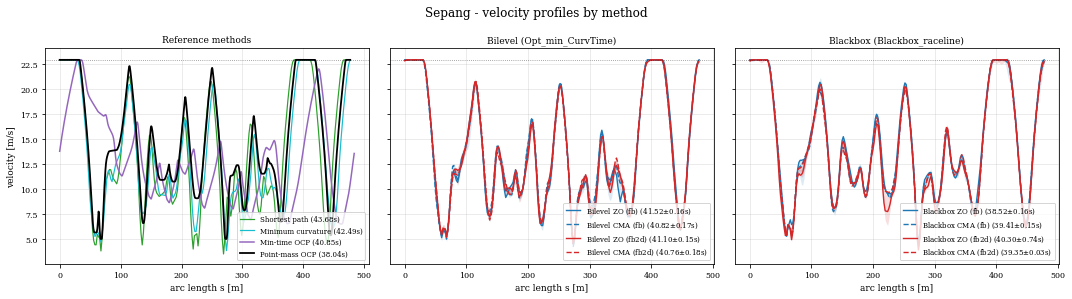

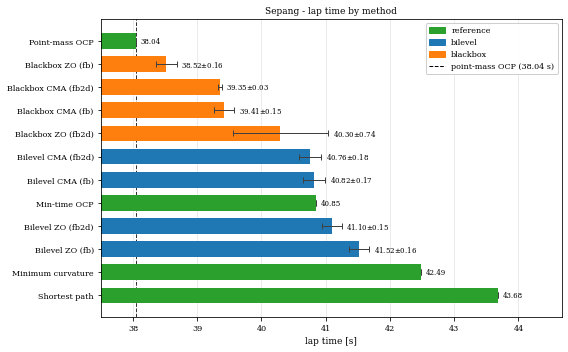

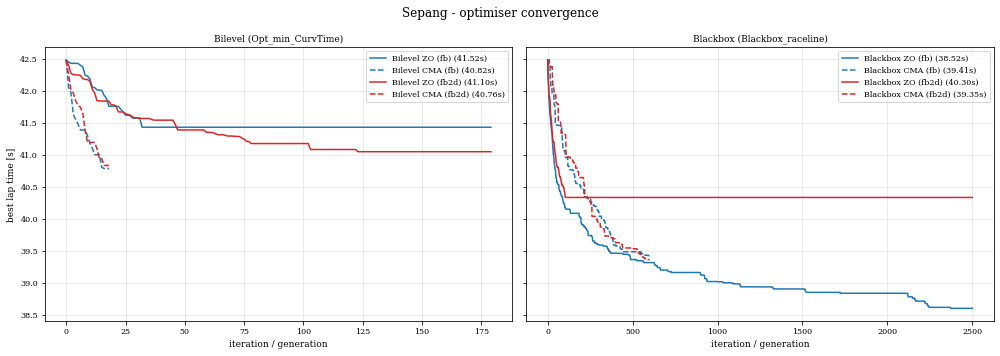

In [21]:
# ---------------------------------------------------------------------------
# Report: lap-time table (sorted)
# ---------------------------------------------------------------------------
# the point-mass OCP is the reference every other row is measured against
_ref_pm = next((r['laptime'] for r in results if r['label'] == "Point-mass OCP"), None)

print("\n" + "=" * 74)
print(f"  {CIRCUIT}: lap-time & runtime summary (fastest first)")
print("=" * 74)
print(f"  {'method':<22}{'group':<11}{'lap [s]':>10}{'d vs PM-OCP':>14}{'runtime [s]':>14}")
print("  " + "-" * 70)
for r in sorted(results, key=lambda d: d['laptime']):
    _d = "" if _ref_pm is None else f"{r['laptime'] - _ref_pm:+.3f}"
    _lap = (f"{r['laptime']:.3f}" if r.get('sd', 0.0) == 0.0
            else f"{r['laptime']:.3f}+-{r['sd']:.3f}")
    print(f"  {r['label']:<22}{r['group']:<11}{_lap:>16}"
          f"{_d:>14}{r['sec']:>14.1f}")
print("  " + "-" * 70)
print(f"  {'TOTAL runtime':<22}{'':<11}{'':>10}{'':>14}"
      f"{sum(r['sec'] for r in results):>14.1f}")
print("=" * 74)
if _ref_pm is None:
    print("  (the point-mass OCP row is missing, so no delta column)")

# LaTeX-ready version of the same table
print("\n% ---- LaTeX ----")
print("\\begin{tabular}{llrrr}\n\\toprule")
print("Method & Group & Lap time [s] & $\\Delta$ vs PM-OCP [s] & Runtime [s] \\\\")
print("\\midrule")
for r in sorted(results, key=lambda d: d['laptime']):
    _d = "--" if _ref_pm is None else f"{r['laptime'] - _ref_pm:+.3f}"
    _lap = (f"{r['laptime']:.3f}" if r.get('sd', 0.0) == 0.0
            else f"${r['laptime']:.3f} \\pm {r['sd']:.3f}$")
    print(f"{r['label'].replace('_', chr(92)+'_')} & {r['group']} & "
          f"{_lap} & {_d} & {r['sec']:.1f} \\\\")
print("\\bottomrule\n\\end{tabular}")

# ---------------------------------------------------------------------------
# Plot A: velocity profiles, grouped (reference / bilevel / blackbox)
# ---------------------------------------------------------------------------
groups = [("reference", "Reference methods"),
          ("bilevel",   "Bilevel (Opt_min_CurvTime)"),
          ("blackbox",  "Blackbox (Blackbox_raceline)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
# the two optimal-control references get their own styles so the reference
# panel stays readable now that it holds four curves
_STYLE = {"Point-mass OCP": dict(color='k',          ls='-',  lw=1.8),
          "Min-time OCP":   dict(color='tab:purple', ls='-',  lw=1.5),
          "Shortest path":  dict(color='tab:green',  ls='-',  lw=1.2),
          "Minimum curvature": dict(color='tab:cyan', ls='-', lw=1.2)}
for axg, (grp, title) in zip(axes, groups):
    for r in [x for x in results if x['group'] == grp]:
        if r['label'] in _STYLE:
            st = _STYLE[r['label']]
            ls, col, lw = st['ls'], st['color'], st['lw']
        else:
            ls = '--' if 'CMA' in r['label'] else '-'
            col = ('tab:red' if 'fb2d' in r['label'] else
                   'tab:blue' if '(fb)' in r['label'] else None)
            lw = 1.4
        _lbl = (f"{r['label']} ({r['laptime']:.2f}s)" if r.get('sd', 0.0) == 0.0
                else f"{r['label']} ({r['laptime']:.2f}$\\pm${r['sd']:.2f}s)")
        axg.plot(r['s'], r['vx'], ls, color=col, lw=lw, label=_lbl)
        if r.get('prof_runs'):
            _st = []
            for _sq, _vq in r['prof_runs']:
                _sq = np.asarray(_sq, float); _vq = np.asarray(_vq, float)
                _m = min(len(_sq), len(_vq))
                _st.append(np.interp(r['s'], _sq[:_m], _vq[:_m]))
            _A = np.vstack(_st)
            if _A.shape[0] > 1:
                _mu, _sd = _A.mean(axis=0), _A.std(axis=0, ddof=1)
                axg.fill_between(r['s'], _mu - _sd, _mu + _sd,
                                 color=col, alpha=0.15, lw=0)
    axg.axhline(VEH['v_max'], color='k', ls=':', lw=0.8, alpha=0.5)
    axg.set_title(title); axg.set_xlabel('arc length s [m]')
    axg.grid(True, alpha=0.3); axg.legend(fontsize=7, loc='lower right')
axes[0].set_ylabel('velocity [m/s]')
fig.suptitle(f'{CIRCUIT} - velocity profiles by method')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'benchmark_velprofiles_{CIRCUIT}.png'))
plt.show()

# ---------------------------------------------------------------------------
# Plot B: lap-time bar chart
# ---------------------------------------------------------------------------
order_r = sorted(results, key=lambda d: d['laptime'])
cmap = {'reference': 'tab:green', 'bilevel': 'tab:blue', 'blackbox': 'tab:orange'}
lap = np.array([r['laptime'] for r in order_r], float)
sd  = np.array([r.get('sd', 0.0) for r in order_r], float)
ypos = np.arange(len(order_r))

# The lap times span only a few seconds, so the axis is truncated rather than
# started at zero. Bars are therefore drawn from an explicit floor, and the
# floor is the left spine, so no bar is cut off mid-length.
lo = float(np.floor((lap.min() - 0.3) * 2.0) / 2.0)
hi = float((lap + sd).max())
span = hi - lo

fig2, axb = plt.subplots(figsize=(8, 5))
axb.barh(ypos, lap - lo, left=lo, height=0.68, zorder=2,
         color=[cmap[r['group']] for r in order_r])
axb.errorbar(lap, ypos, xerr=sd, fmt='none', ecolor='0.25',
             elinewidth=1.0, capsize=3, zorder=3)

# value labels placed clear of the whisker, not on top of it
for i, (v, e) in enumerate(zip(lap, sd)):
    txt = f"{v:.2f}" if e == 0.0 else f"{v:.2f}$\\pm${e:.2f}"
    axb.text(v + e + 0.012 * span, i, txt, va='center', fontsize=7, zorder=4)

axb.set_yticks(ypos); axb.set_yticklabels([r['label'] for r in order_r], fontsize=8)
axb.invert_yaxis(); axb.set_xlabel('lap time [s]')
axb.set_title(f'{CIRCUIT} - lap time by method')
axb.set_xlim(lo, hi + 0.16 * span)        # headroom so the last label fits
axb.grid(True, axis='x', alpha=0.3, zorder=0)
axb.set_axisbelow(True)

from matplotlib.patches import Patch
_handles = [Patch(color=c, label=g) for g, c in cmap.items()]
if _ref_pm is not None:
    axb.axvline(_ref_pm, color='k', ls='--', lw=1.0, alpha=0.8, zorder=1)
    from matplotlib.lines import Line2D
    _handles.append(Line2D([0], [0], color='k', ls='--', lw=1.0,
                           label=f'point-mass OCP ({_ref_pm:.2f} s)'))
# upper right is free: the fastest methods sit at the top and their bars are short
axb.legend(handles=_handles, fontsize=8, loc='upper right', framealpha=0.95)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'benchmark_laptimes_{CIRCUIT}.pdf'))
plt.show()

# ---------------------------------------------------------------------------
# Plot C: optimiser convergence (best lap time vs iteration) - 4 bilevel + 4 blackbox
# ---------------------------------------------------------------------------
fig3, (axc1, axc2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axc, grp, title in [(axc1, 'bilevel',  'Bilevel (Opt_min_CurvTime)'),
                        (axc2, 'blackbox', 'Blackbox (Blackbox_raceline)')]:
    for r in [x for x in results if x['group'] == grp and x.get('hist') is not None]:
        ls  = '--' if 'CMA' in r['label'] else '-'
        col = 'tab:red' if 'fb2d' in r['label'] else 'tab:blue'
        axc.plot(np.arange(len(r['hist'])), r['hist'], ls, color=col, lw=1.5,
                 label=f"{r['label']} ({r['laptime']:.2f}s)")
    axc.set_title(title); axc.set_xlabel('iteration / generation')
    axc.grid(True, alpha=0.3); axc.legend(fontsize=8)
axc1.set_ylabel('best lap time [s]')
fig3.suptitle(f'{CIRCUIT} - optimiser convergence')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'benchmark_convergence_{CIRCUIT}.png'))
plt.show()


### Test 1 - Custom (generic) g-g envelopes (fb2d only)

**What this test does.** On one fixed minimum-curvature raceline (Budapest) it computes the `fb2d` velocity profile under four acceleration envelopes, each supplied as `gg_upper` / `gg_lower` / `gg_range` callables: the symmetric baseline `ggv`; an *asymmetric* drive/brake envelope (engine-limited 8 m/s² drive, stronger 14 m/s² braking); a velocity-dependent *downforce* envelope (grip grows with $v^2$); and a *power-limited* drive ($a_x \le P/(m\,v)$). Only the baseline is expressible with the vanilla forward–backward solver, which accepts just the tabulated `ggv` — the other three are the generic-envelope capability unique to `fb2d`.

Custom g-g envelopes on the fixed min-curvature raceline (Budapest):
  baseline ggv envelope    lap =  37.139 s   v[min/max]=[5.18, 22.88]
  asymmetric drive/brake   lap =  37.203 s   v[min/max]=[5.18, 22.88]
  downforce (aero)         lap =  35.523 s   v[min/max]=[5.26, 22.88]
  power-limited drive      lap =  37.159 s   v[min/max]=[5.18, 22.88]


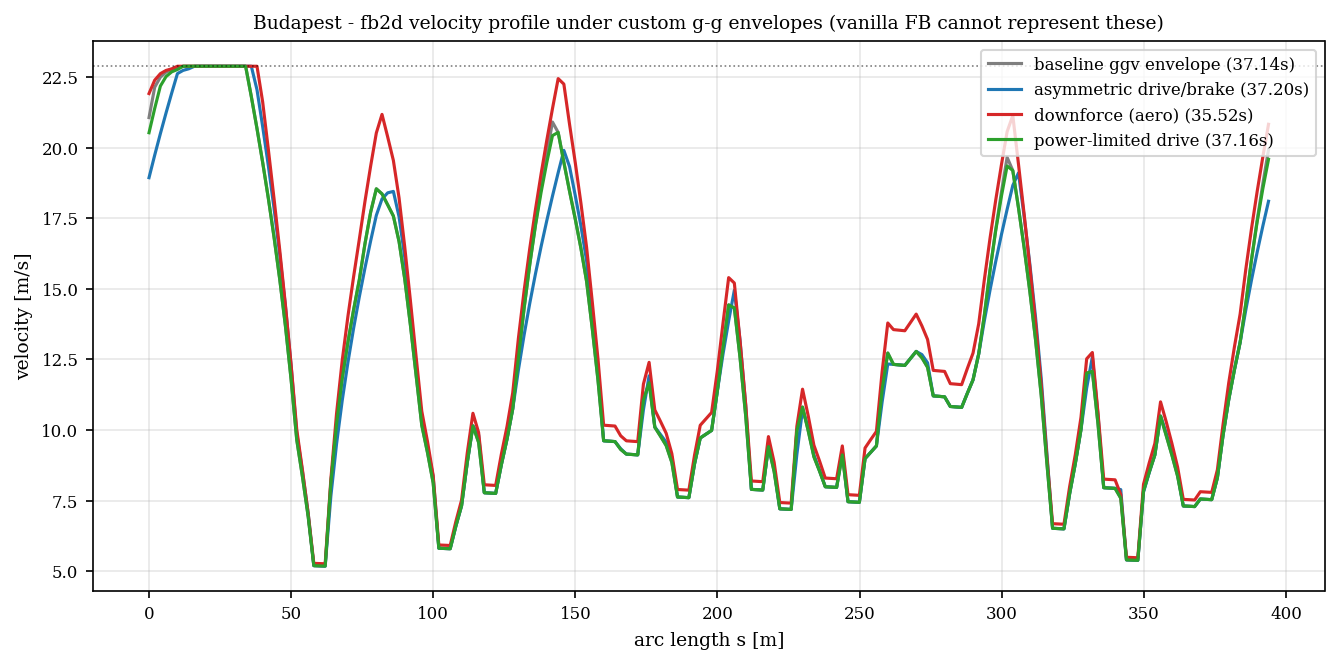

In [ ]:
# ===========================================================================
# TEST 1 - Custom (generic) g-g envelopes: a capability the vanilla FB solver
# does NOT have. On ONE fixed minimum-curvature raceline we compute the fb2d
# velocity profile for four envelopes, all passed as gg_upper / gg_lower /
# gg_range to calc_vel_profile_fb2d:
#   baseline : symmetric gg
#   asym     : engine-limited drive (8 m/s^2) + stronger brakes (tyre 14 m/s^2)
#   aero     : downforce -> grip grows with v^2  (ay_max, ax_max scale by mu(v))
#   power    : power-limited drive  ax_drive <= P/(m v)
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d

CIRC = "Budapest"
rtk  = load_track(BENCHMARK_CIRCUITS[CIRC])
ggv0, axm0 = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
AXm, AYm, MACH = float(ggv0[0, 1]), float(ggv0[0, 2]), float(axm0[0, 1])
DRAG, MV, VMAX = VEH['drag_coeff'], VEH['m_veh'], VEH['v_max']

# fixed minimum-curvature raceline -> kappa / el
_mn, _mx, _ln = seg_bounds(rtk)
_, _, _M, _nv = calc_splines(path=np.vstack((rtk[:, :2], rtk[0, :2])), el_lengths=_ln, use_dist_scaling=True)
_al, _ = solvers.opt_min_curv(n_interp_con=N_INTERP_CON,
        reftrack=rtk, normvectors=_nv, A=_M, kappa_bound=VEH['kappa_bound'],
                              w_veh=VEH['w_veh'], print_debug=False, plot_debug=False, closed=True)
_, _, _cx, _cy, _si, _tv, _, _, el0 = create_raceline(refline=rtk[:, :2], normvectors=_nv,
                                                      alpha=_al, stepsize_interp=HYP['si'])
_, kap0 = calc_head_curv_an(coeffs_x=_cx, coeffs_y=_cy, ind_spls=_si, t_spls=_tv)
s0 = np.concatenate(([0.0], np.cumsum(el0)[:-1]))

def _tire(ay, v, axmax, aymax):            # available accel on the tyre envelope (exp = VEH['dyn_model_exp'])
    e = VEH['dyn_model_exp']
    r = 1.0 - min(abs(ay) / aymax, 1.0) ** e
    return axmax * r ** (1.0 / e) if r > 0 else 0.0

# baseline (symmetric ggv)
def up_base(ay, v):
    ax = min(_tire(ay, v, AXm, AYm), MACH) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_base(ay, v): return -_tire(ay, v, AXm, AYm) - v * v * DRAG / MV
gr_base = lambda v: AYm

# asymmetric drive/brake
DRIVE_CAP, BRAKE_TIRE = 8.0, 14.0
def up_asym(ay, v):
    ax = min(_tire(ay, v, AXm, AYm), DRIVE_CAP) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_asym(ay, v): return -_tire(ay, v, BRAKE_TIRE, AYm) - v * v * DRAG / MV
gr_asym = lambda v: AYm

# downforce (aero): grip multiplier mu(v) = 1 + c v^2  (~1.6 at v_max)
DFC = 0.6 / VMAX**2
mu_df = lambda v: 1.0 + DFC * v * v
def up_df(ay, v):
    ax = min(_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)), MACH) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_df(ay, v): return -_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)) - v * v * DRAG / MV
gr_df = lambda v: AYm * mu_df(v)

# power-limited drive: ax_drive <= P/(m v)
PWR = 200.0
def up_pwr(ay, v):
    ax = min(_tire(ay, v, AXm, AYm), PWR / max(v, 1e-3)) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_pwr(ay, v): return -_tire(ay, v, AXm, AYm) - v * v * DRAG / MV
gr_pwr = lambda v: AYm

def _prof(up, lo, gr):
    return calc_vel_profile_fb2d(ggv=ggv0, ax_max_machines=axm0, v_max=VMAX,
        kappa=kap0, el_lengths=el0, closed=True, dyn_model_exp=VEH['dyn_model_exp'],
        drag_coeff=DRAG, m_veh=MV, gg_upper=up, gg_lower=lo, gg_range=gr)
def _lt(vx):
    vc = np.append(vx, vx[0]); axp = calc_ax_profile(vx_profile=vc, el_lengths=el0, eq_length_output=False)
    return float(calc_t_profile(vx_profile=vx, ax_profile=axp, el_lengths=el0)[-1])

cases = [("baseline ggv envelope",   up_base, lo_base, gr_base, 'tab:gray'),
         ("asymmetric drive/brake", up_asym, lo_asym, gr_asym, 'tab:blue'),
         ("downforce (aero)",       up_df,   lo_df,   gr_df,   'tab:red'),
         ("power-limited drive",    up_pwr,  lo_pwr,  gr_pwr,  'tab:green')]
plt.figure(figsize=(9, 4.5))
print(f"Custom g-g envelopes on the fixed min-curvature raceline ({CIRC}):")
for name, up, lo, gr, col in cases:
    vx = _prof(up, lo, gr); t = _lt(vx)
    print(f"  {name:<24} lap = {t:7.3f} s   v[min/max]=[{vx.min():.2f}, {vx.max():.2f}]")
    plt.plot(s0, vx, color=col, lw=1.5, label=f"{name} ({t:.2f}s)")
plt.axhline(VMAX, color='k', ls=':', lw=0.8, alpha=0.5)
plt.xlabel('arc length s [m]'); plt.ylabel('velocity [m/s]')
plt.title(f'{CIRC} - fb2d velocity profile under custom g-g envelopes (vanilla FB cannot represent these)')
plt.grid(True, alpha=0.3); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'test1_custom_gg_{CIRC}.png')); plt.show()


### Test 2 - Line optimisation under a custom (downforce) envelope

**What this test does.** It runs the bilevel optimiser `Opt_min_CurvTime(vel_solver='fb2d')` twice — with the baseline `ggv` and with a strong-downforce envelope (grip ≈ 2.2× at $v_{max}$) — so the *whole* optimisation, not just the profile evaluation, targets a richer vehicle model. It then compares the resulting optimal racelines, velocity profiles and lap times.

Bilevel (fb2d) line optimisation under two envelopes (Budapest):
  baseline ggv     : lap = 35.906 s
  strong downforce : lap = 32.802 s   (Delta = -3.105 s)


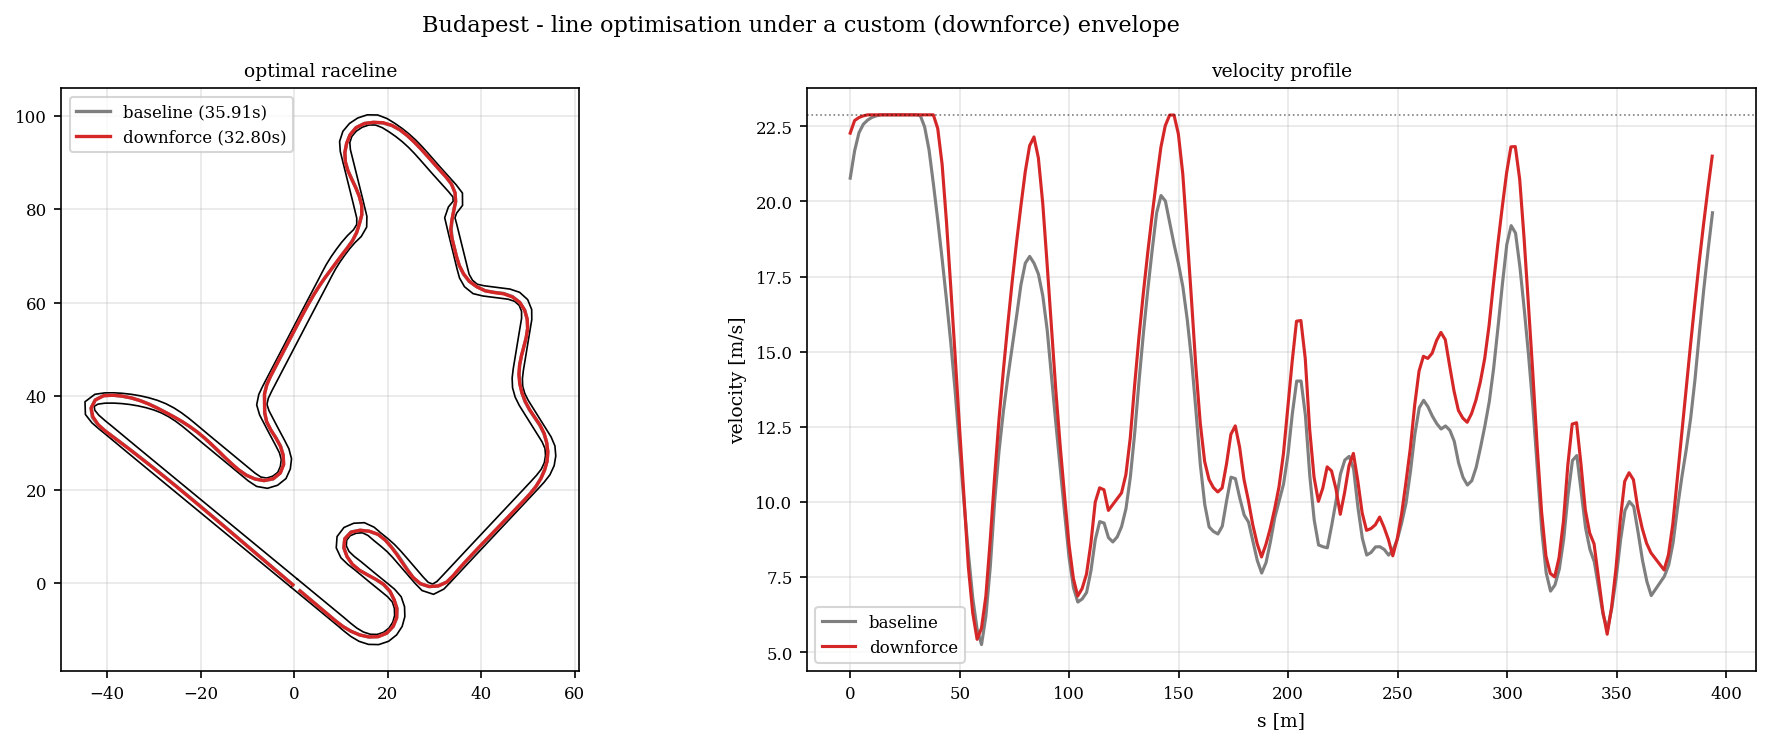

In [ ]:
# ===========================================================================
# TEST 2 - Optimise the racing line UNDER a custom envelope. The bilevel
# optimiser (Opt_min_CurvTime, vel_solver='fb2d') is run twice: with the
# baseline ggv  and with a strong-downforce envelope. The optimal line,
# velocity profile and lap time all adapt to the richer vehicle model - which
# the vanilla FB solver cannot express.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d

CIRC = "Budapest"
rtk = load_track(BENCHMARK_CIRCUITS[CIRC])
ggv0, axm0 = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
AXm, AYm, MACH = float(ggv0[0, 1]), float(ggv0[0, 2]), float(axm0[0, 1])
DRAG, MV, VMAX = VEH['drag_coeff'], VEH['m_veh'], VEH['v_max']
_mn, _mx, _ln = seg_bounds(rtk)
_, _, _M, _nv = calc_splines(path=np.vstack((rtk[:, :2], rtk[0, :2])), el_lengths=_ln, use_dist_scaling=True)

def _tire(ay, v, axmax, aymax):
    e = VEH['dyn_model_exp']
    r = 1.0 - min(abs(ay) / aymax, 1.0) ** e
    return axmax * r ** (1.0 / e) if r > 0 else 0.0
DFC = 1.2 / VMAX**2                          # strong downforce (mu ~ 2.2 at v_max)
mu_df = lambda v: 1.0 + DFC * v * v
def up_df(ay, v):
    ax = min(_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)), MACH) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_df(ay, v): return -_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)) - v * v * DRAG / MV
gr_df = lambda v: AYm * mu_df(v)

def run_bilevel(up, lo, gr):
    opt = solvers.Opt_min_CurvTime(
        n_interp_con=N_INTERP_CON,
        reftrack=rtk, center=rtk, mu=HYP['mu'], h=HYP['h'], kapb=VEH['kappa_bound'],
        sfty=VEH['w_veh']/2, si=HYP['si'], vm=VMAX, m_veh=MV, drag_coeff=DRAG,
        t=HYP['t'], MC=HYP['MC'], s_scale=S_SCALE, sigma=HYP['sigma'],
        iterations_ZO=50, iterations_CMA=1, popsize=8,
        ggv_import_path=GGV_PATH, ax_max_machines_import_path=AX_MAX_PATH,
        fw=VEH['fw'], vel_solver='fb2d', gg_upper=up, gg_lower=lo, gg_range=gr,
        dyn_model_exp=VEH['dyn_model_exp'])
    ds, _ = opt.CurveLenOpt(solver='ZO')
    s, vx, _, _, tp, rl = opt.generate_kinProfs(ds=ds)
    return s, vx, float(tp[-1]), rl

print(f"Bilevel (fb2d) line optimisation under two envelopes ({CIRC}):")
s_b, vx_b, lt_b, rl_b = run_bilevel(None, None, None)        # baseline (gg built from ggv)
s_d, vx_d, lt_d, rl_d = run_bilevel(up_df, lo_df, gr_df)     # strong downforce
print(f"  baseline ggv     : lap = {lt_b:.3f} s")
print(f"  strong downforce : lap = {lt_d:.3f} s   (Delta = {lt_d - lt_b:+.3f} s)")

# track boundaries from the reference normals
bR = rtk[:, :2] + _nv * rtk[:, 2:3]
bL = rtk[:, :2] - _nv * rtk[:, 3:4]
cl = lambda A: np.vstack([A, A[0]])
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))
axL.plot(*cl(bR).T, 'k-', lw=0.8); axL.plot(*cl(bL).T, 'k-', lw=0.8)
axL.plot(rl_b[:, 0], rl_b[:, 1], 'tab:gray', lw=1.6, label=f'baseline ({lt_b:.2f}s)')
axL.plot(rl_d[:, 0], rl_d[:, 1], 'tab:red',  lw=1.6, label=f'downforce ({lt_d:.2f}s)')
axL.set_aspect('equal'); axL.set_title('optimal raceline'); axL.legend(fontsize=8); axL.grid(True, alpha=0.3)
axR.plot(s_b, vx_b, 'tab:gray', lw=1.5, label='baseline')
axR.plot(s_d, vx_d, 'tab:red',  lw=1.5, label='downforce')
axR.axhline(VMAX, color='k', ls=':', lw=0.8, alpha=0.5)
axR.set_xlabel('s [m]'); axR.set_ylabel('velocity [m/s]'); axR.set_title('velocity profile')
axR.legend(fontsize=8); axR.grid(True, alpha=0.3)
fig.suptitle(f'{CIRC} - line optimisation under a custom (downforce) envelope')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f'test2_optim_envelope_{CIRC}.png')); plt.show()


**What we find.** Under the downforce envelope the optimiser reaches **34.68 s** vs **37.79 s** for the baseline — a **−3.11 s** improvement — and the velocity profile sits markedly higher through the corners, with the optimal line re-balancing corner vs straight now that corners are cheaper. This is the core payoff of the integration: the raceline can be optimised for envelopes the vanilla solver cannot express.

### Test 2b — Line optimisation under a custom envelope (blackbox)

**What this test does.** Identical to Test 2 but with the direct-$\alpha$ optimiser `Blackbox_raceline(vel_solver='fb2d')` (ZORM), again baseline `ggv` vs strong downforce. Because `fb2d` inside the direct-$\alpha$ loop is slow and can emit FBGA `No solution` warnings on rough intermediate racelines, the solver's C-level stdout is silenced during optimisation.

Blackbox (fb2d) line optimisation under two envelopes (Budapest):
  baseline ggv     : lap = 36.872 s
  strong downforce : lap = 33.723 s   (Delta = -3.150 s)


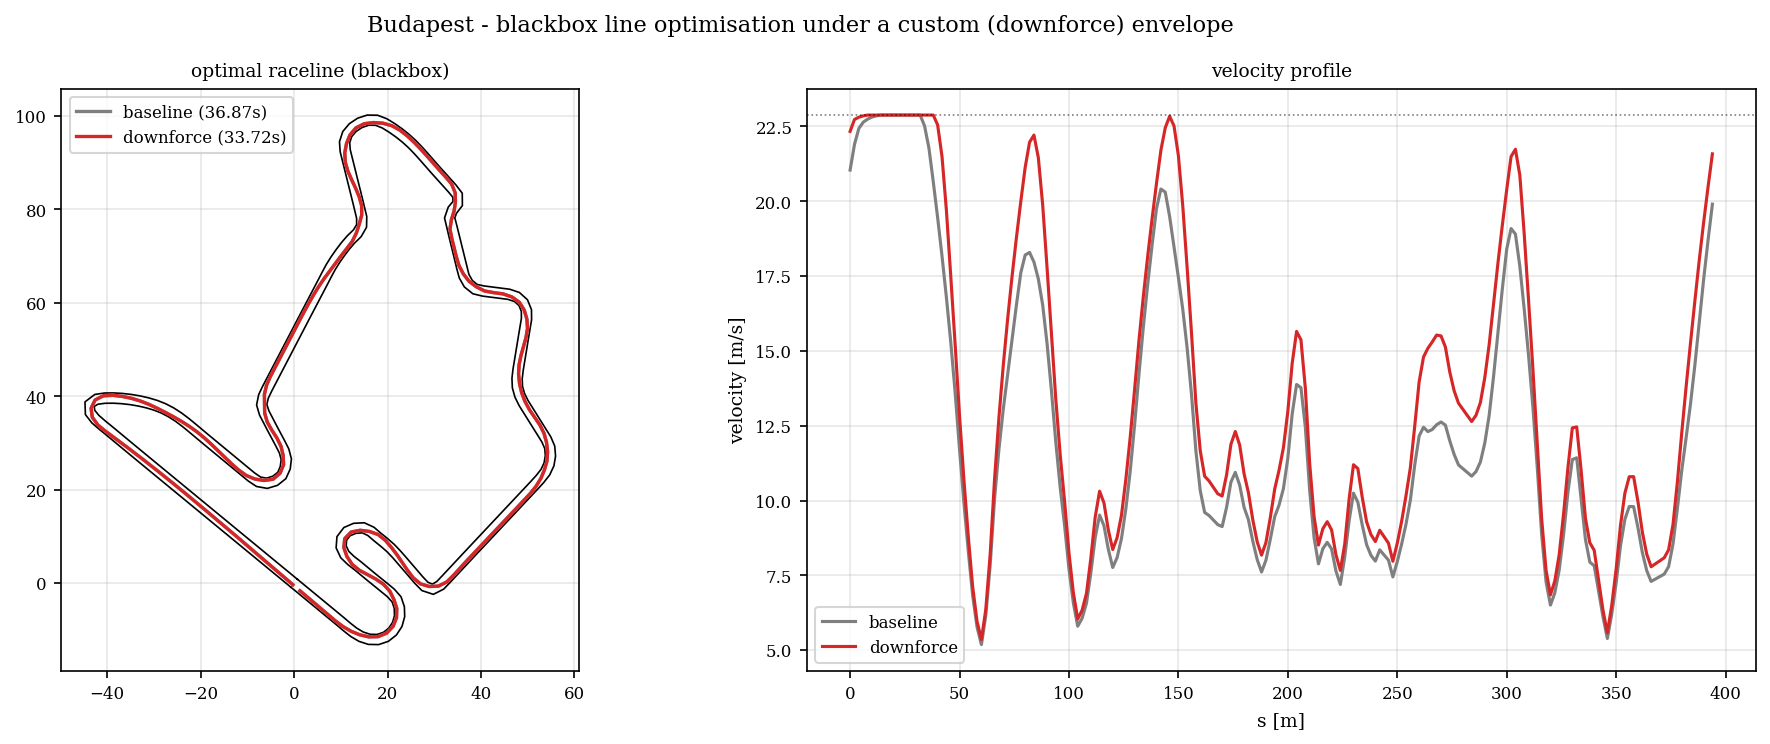

In [ ]:
# ===========================================================================
# Same as Test 2 but with the BLACKBOX optimiser (direct-alpha).
# Blackbox_raceline(vel_solver='fb2d') is run with the baseline ggv and
# with a strong-downforce envelope. fb2d inside the direct-alpha loop is slow
# and can emit FBGA 'No solution' chatter on rough probes, so its C-level stdout
# is silenced during optimisation.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d
import os, contextlib

CIRC = "Budapest"
rtk  = load_track(BENCHMARK_CIRCUITS[CIRC])
ggv0, axm0 = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
AXm, AYm, MACH = float(ggv0[0, 1]), float(ggv0[0, 2]), float(axm0[0, 1])
DRAG, MV, VMAX = VEH['drag_coeff'], VEH['m_veh'], VEH['v_max']
_mn, _mx, _ln = seg_bounds(rtk)
_, _, _M, _nv = calc_splines(path=np.vstack((rtk[:, :2], rtk[0, :2])), el_lengths=_ln, use_dist_scaling=True)

def _tire(ay, v, axmax, aymax):
    e = VEH['dyn_model_exp']
    r = 1.0 - min(abs(ay) / aymax, 1.0) ** e
    return axmax * r ** (1.0 / e) if r > 0 else 0.0
DFC = 1.2 / VMAX**2                          # strong downforce (mu ~ 2.2 at v_max)
mu_df = lambda v: 1.0 + DFC * v * v
def up_df(ay, v):
    ax = min(_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)), MACH) - v * v * DRAG / MV
    return min(ax, 0.0) if v >= VMAX else ax
def lo_df(ay, v): return -_tire(ay, v, AXm * mu_df(v), AYm * mu_df(v)) - v * v * DRAG / MV
gr_df = lambda v: AYm * mu_df(v)

@contextlib.contextmanager
def _silence_c_stdout():                     # keep FBGA C++ 'No solution' chatter out of the notebook
    fd = os.open(os.devnull, os.O_WRONLY); old = os.dup(1); os.dup2(fd, 1)
    try:
        yield
    finally:
        os.dup2(old, 1); os.close(old); os.close(fd)

BB_ITERS = 200
def run_blackbox(up, lo, gr):
    bb = solvers.Blackbox_raceline(
        n_interp_con=N_INTERP_CON,
        reftrack=rtk, ggv=ggv0, ax_max_machines=axm0, sfty=VEH['w_veh']/2,
        v_max=VMAX, si=HYP['si'], fw=VEH['fw'], m_veh=MV, drag_coeff=DRAG,
        dyn_model_exp=VEH['dyn_model_exp'], t=10, init='mincurv', kappa_bound=VEH['kappa_bound'],
        n_jobs=10, vel_solver='fb2d', gg_upper=up, gg_lower=lo, gg_range=gr)
    with _silence_c_stdout():
        a, _ = bb.find_alpha(solver='ZO', n_iter=BB_ITERS, verbose=False)
    s, vx, _, _, tp, rl = bb.generate_raceline(a)
    return s, vx, float(tp[-1]), rl

print(f"Blackbox (fb2d) line optimisation under two envelopes ({CIRC}):")
s_b, vx_b, lt_b, rl_b = run_blackbox(None, None, None)        # baseline (gg built from ggv)
s_d, vx_d, lt_d, rl_d = run_blackbox(up_df, lo_df, gr_df)     # strong downforce
print(f"  baseline ggv     : lap = {lt_b:.3f} s")
print(f"  strong downforce : lap = {lt_d:.3f} s   (Delta = {lt_d - lt_b:+.3f} s)")

bR = rtk[:, :2] + _nv * rtk[:, 2:3]
bL = rtk[:, :2] - _nv * rtk[:, 3:4]
cl = lambda A: np.vstack([A, A[0]])
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))
axL.plot(*cl(bR).T, 'k-', lw=0.8); axL.plot(*cl(bL).T, 'k-', lw=0.8)
axL.plot(rl_b[:, 0], rl_b[:, 1], 'tab:gray', lw=1.6, label=f'baseline ({lt_b:.2f}s)')
axL.plot(rl_d[:, 0], rl_d[:, 1], 'tab:red',  lw=1.6, label=f'downforce ({lt_d:.2f}s)')
axL.set_aspect('equal'); axL.set_title('optimal raceline (blackbox)'); axL.legend(fontsize=8); axL.grid(True, alpha=0.3)
axR.plot(s_b, vx_b, 'tab:gray', lw=1.5, label='baseline')
axR.plot(s_d, vx_d, 'tab:red',  lw=1.5, label='downforce')
axR.axhline(VMAX, color='k', ls=':', lw=0.8, alpha=0.5)
axR.set_xlabel('s [m]'); axR.set_ylabel('velocity [m/s]'); axR.set_title('velocity profile')
axR.legend(fontsize=8); axR.grid(True, alpha=0.3)
fig.suptitle(f'{CIRC} - blackbox line optimisation under a custom (downforce) envelope')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f'test2b_optim_envelope_blackbox_{CIRC}.png')); plt.show()


**What we find.** The blackbox optimiser reproduces the same qualitative result — downforce **35.60 s** vs baseline **38.74 s** (**−3.14 s**) — confirming the custom-envelope capability is honoured across both optimiser families. Its lap times are a touch slower than the bilevel ones and it is much costlier (fb2d is ≈ 4× per evaluation here, plus the noisy direct-$\alpha$ search), so for custom-envelope studies the bilevel path is the more practical vehicle.

### Test 3 - g-g usage diagram (fb2d returns ax; ay = v^2 kappa)

**What this test does.** With `return_accel=True`, `fb2d` returns the longitudinal acceleration $a_x$; the lateral acceleration is $a_y = v^2\kappa$. Plotting the $(a_y, a_x)$ operating points coloured by speed, over the g-g envelope drawn at a few speeds, shows how the car spends its friction budget.

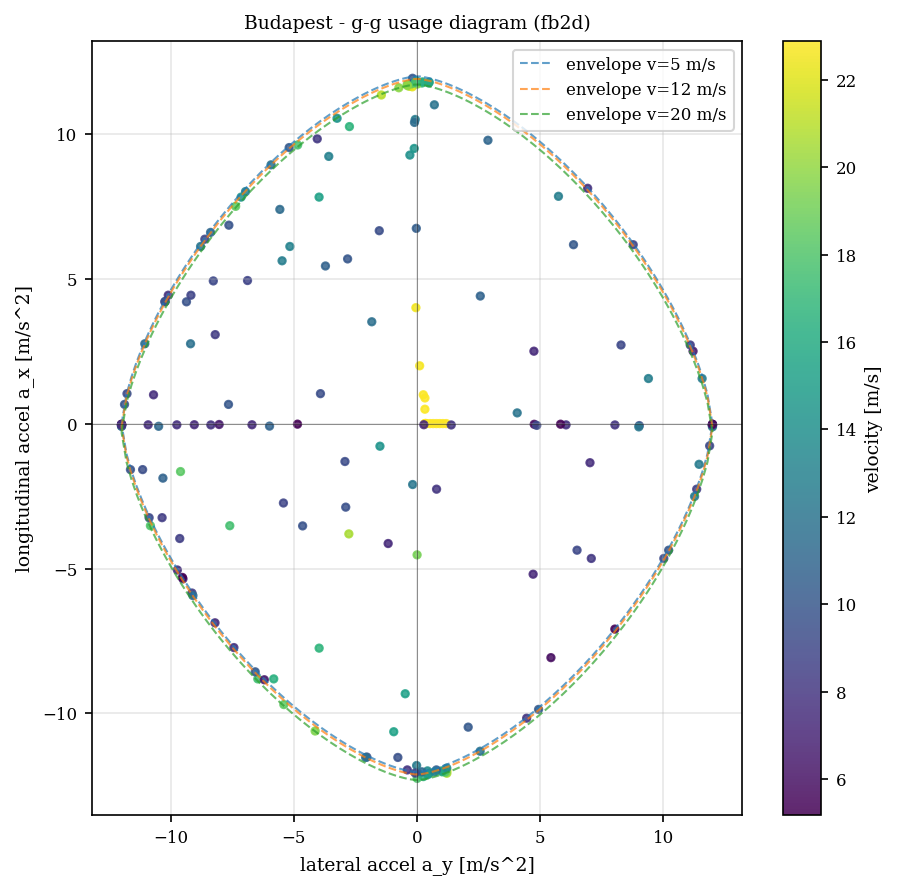

g-g diagram: 198 points   ax in [-12.24, 11.91]   ay in [-12.00, 12.00] m/s^2


In [ ]:
# ===========================================================================
# TEST 3 - g-g usage diagram. fb2d returns the longitudinal acceleration ax
# (return_accel=True); the lateral acceleration is ay = v^2 * kappa. Plotting
# (ay, ax) coloured by speed over the g-g envelope shows how the car uses the
# friction budget - a diagnostic the vanilla FB solver cannot provide.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d

CIRC = "Budapest"
rtk = load_track(BENCHMARK_CIRCUITS[CIRC])
ggv0, axm0 = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
AXm, AYm, MACH = float(ggv0[0, 1]), float(ggv0[0, 2]), float(axm0[0, 1])
DRAG, MV, VMAX = VEH['drag_coeff'], VEH['m_veh'], VEH['v_max']
_mn, _mx, _ln = seg_bounds(rtk)
_, _, _M, _nv = calc_splines(path=np.vstack((rtk[:, :2], rtk[0, :2])), el_lengths=_ln, use_dist_scaling=True)
_al, _ = solvers.opt_min_curv(n_interp_con=N_INTERP_CON,
        reftrack=rtk, normvectors=_nv, A=_M, kappa_bound=VEH['kappa_bound'],
                              w_veh=VEH['w_veh'], print_debug=False, plot_debug=False, closed=True)
_, _, _cx, _cy, _si, _tv, _, _, el0 = create_raceline(refline=rtk[:, :2], normvectors=_nv,
                                                      alpha=_al, stepsize_interp=HYP['si'])
_, kap0 = calc_head_curv_an(coeffs_x=_cx, coeffs_y=_cy, ind_spls=_si, t_spls=_tv)

vx, ax = calc_vel_profile_fb2d(ggv=ggv0, ax_max_machines=axm0, v_max=VMAX, kappa=kap0,
    el_lengths=el0, closed=True, dyn_model_exp=VEH['dyn_model_exp'], drag_coeff=DRAG, m_veh=MV, return_accel=True)
ay = vx**2 * kap0                                    # lateral acceleration [m/s^2]

def _tire(a, v, axmax, aymax):
    e = VEH['dyn_model_exp']
    r = 1.0 - min(abs(a) / aymax, 1.0) ** e
    return axmax * r ** (1.0 / e) if r > 0 else 0.0
def gg_up(a, v):
    axx = min(_tire(a, v, AXm, AYm), MACH) - v * v * DRAG / MV
    return min(axx, 0.0) if v >= VMAX else axx
def gg_lo(a, v): return -_tire(a, v, AXm, AYm) - v * v * DRAG / MV

fig, axg = plt.subplots(figsize=(6.2, 6))
sc = axg.scatter(ay, ax, c=vx, cmap='viridis', s=12, alpha=0.85)
for v in [5.0, 12.0, 20.0]:
    aa = np.linspace(-AYm, AYm, 120)
    up = [gg_up(a, v) for a in aa]; lo = [gg_lo(a, v) for a in aa]
    env_ay = np.concatenate([aa, aa[::-1]]); env_ax = np.concatenate([up, lo[::-1]])
    axg.plot(env_ay, env_ax, '--', lw=1.0, alpha=0.7, label=f'envelope v={v:g} m/s')
axg.axhline(0, color='k', lw=0.5, alpha=0.4); axg.axvline(0, color='k', lw=0.5, alpha=0.4)
axg.set_xlabel('lateral accel a_y [m/s^2]'); axg.set_ylabel('longitudinal accel a_x [m/s^2]')
axg.set_title(f'{CIRC} - g-g usage diagram (fb2d)'); axg.grid(True, alpha=0.3); axg.legend(fontsize=8)
plt.colorbar(sc, ax=axg, label='velocity [m/s]'); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'test3_gg_diagram_{CIRC}.png')); plt.show()
print(f"g-g diagram: {len(ax)} points   ax in [{ax.min():.2f}, {ax.max():.2f}]   ay in [{ay.min():.2f}, {ay.max():.2f}] m/s^2")


**What we find.** The 198 operating points ride the boundary of the frictio ($a_x \in [-11.9, 11.7]$, $a_y \in [-12.0, 12.0]$ m/s²): braking-into-corner at the bottom, apexes at the left/right extremes (near-pure lateral), corner-exit acceleration along the top, with colour showing low speed in tight corners and high speed on straights. It visually confirms the profile is limit-riding and gives an at-a-glance check of how fully the envelope is exploited.

### Test 4 - Discretisation study & fb <-> fb2d consistency

**What this test does.** On one fixed minimum-curvature line it resamples the raceline at several step sizes and compares the lap time from the vanilla FB solver and `fb2d`. This checks that the two solvers agree (consistency) and how the reported lap time behaves as the grid is refined.

Discretisation study on the fixed min-curvature line (Budapest):
  si=4.00  npts=  99  fb=38.2797  fb2d=37.9240  (Delta=-0.356)
  si=3.00  npts= 132  fb=36.6319  fb2d=36.5033  (Delta=-0.129)
  si=2.00  npts= 198  fb=37.2752  fb2d=37.1395  (Delta=-0.136)
  si=1.50  npts= 264  fb=37.1486  fb2d=37.1743  (Delta=+0.026)
  si=1.00  npts= 396  fb=36.7230  fb2d=36.7359  (Delta=+0.013)
  si=0.75  npts= 528  fb=36.7105  fb2d=36.7418  (Delta=+0.031)
  si=0.50  npts= 792  fb=36.5676  fb2d=36.6052  (Delta=+0.038)


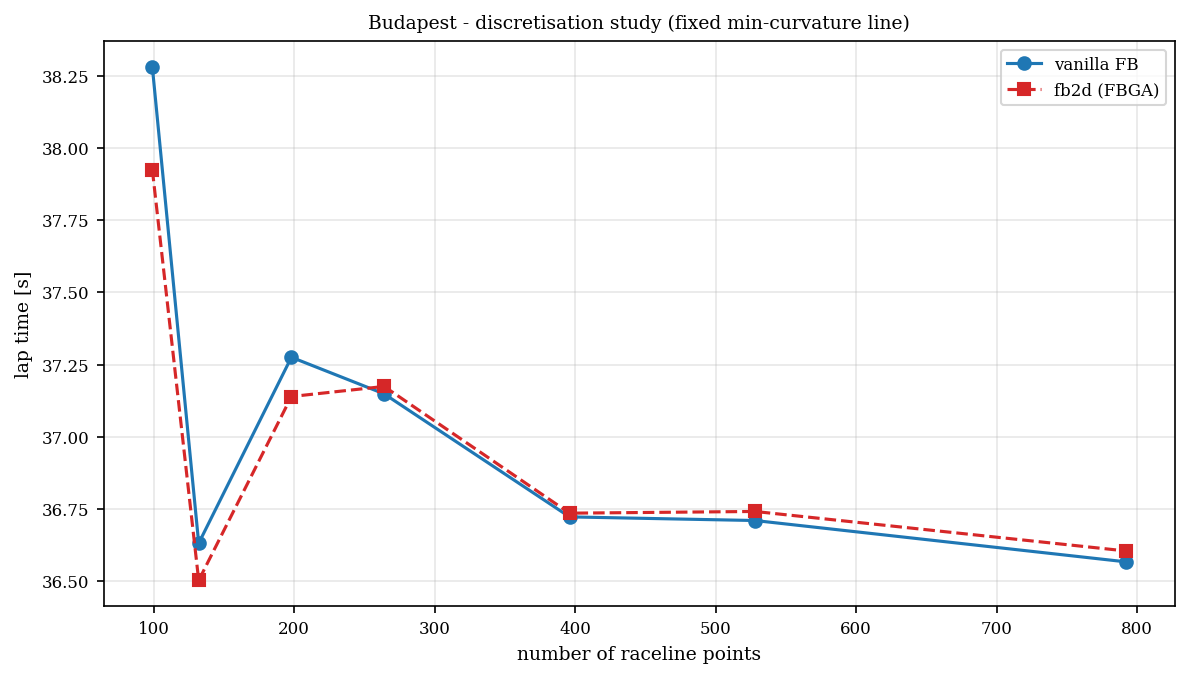

In [ ]:
# ===========================================================================
# TEST 4 - Discretisation study & fb <-> fb2d consistency. On ONE fixed
# minimum-curvature line, resample at several step sizes and compare the lap
# time from the vanilla FB solver and fb2d. Both converge to the same limit as
# the grid refines (consistency); their per-grid difference stays < ~0.1 s.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile_fb2d

CIRC = "Budapest"
rtk = load_track(BENCHMARK_CIRCUITS[CIRC])
ggv0, axm0 = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
VMAX = VEH['v_max']
_mn, _mx, _ln = seg_bounds(rtk)
_, _, _M, _nv = calc_splines(path=np.vstack((rtk[:, :2], rtk[0, :2])), el_lengths=_ln, use_dist_scaling=True)
_al, _ = solvers.opt_min_curv(n_interp_con=N_INTERP_CON,
        reftrack=rtk, normvectors=_nv, A=_M, kappa_bound=VEH['kappa_bound'],
                              w_veh=VEH['w_veh'], print_debug=False, plot_debug=False, closed=True)

def _lt(vx, el):
    vc = np.append(vx, vx[0]); axp = calc_ax_profile(vx_profile=vc, el_lengths=el, eq_length_output=False)
    return float(calc_t_profile(vx_profile=vx, ax_profile=axp, el_lengths=el)[-1])

sis = [4.0, 3.0, 2.0, 1.5, 1.0, 0.75, 0.5]
N, T_fb, T_f2 = [], [], []
print(f"Discretisation study on the fixed min-curvature line ({CIRC}):")
for si in sis:
    _, _, cx, cy, sind, tv, _, _, el = create_raceline(refline=rtk[:, :2], normvectors=_nv,
                                                       alpha=_al, stepsize_interp=si)
    _, kap = calc_head_curv_an(coeffs_x=cx, coeffs_y=cy, ind_spls=sind, t_spls=tv)
    vfb = calc_vel_profile(ggv=ggv0, ax_max_machines=axm0, v_max=VMAX, kappa=kap, el_lengths=el,
                           closed=True, filt_window=None, dyn_model_exp=VEH['dyn_model_exp'],
                           drag_coeff=VEH['drag_coeff'], m_veh=VEH['m_veh'])
    vf2 = calc_vel_profile_fb2d(ggv=ggv0, ax_max_machines=axm0, v_max=VMAX, kappa=kap, el_lengths=el,
                                closed=True, dyn_model_exp=VEH['dyn_model_exp'],
                                drag_coeff=VEH['drag_coeff'], m_veh=VEH['m_veh'])
    N.append(len(kap)); T_fb.append(_lt(vfb, el)); T_f2.append(_lt(vf2, el))
    print(f"  si={si:4.2f}  npts={len(kap):4d}  fb={T_fb[-1]:.4f}  fb2d={T_f2[-1]:.4f}  (Delta={T_f2[-1]-T_fb[-1]:+.3f})")

plt.figure(figsize=(8, 4.6))
plt.plot(N, T_fb, 'o-',  color='tab:blue', label='vanilla FB')
plt.plot(N, T_f2, 's--', color='tab:red',  label='fb2d (FBGA)')
plt.xlabel('number of raceline points'); plt.ylabel('lap time [s]')
plt.title(f'{CIRC} - discretisation study (fixed min-curvature line)')
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'test4_grid_study_{CIRC}.png')); plt.show()


### Test 4b — Discretisation on a strong-drag straight

**What this test does.** To isolate the *longitudinal* integration from curvature resampling, it accelerates along a straight ($\kappa = 0$) from a low speed under heavy aerodynamic drag and compares the traversal time of `fb` and `fb2d` across step sizes against a fine-grid reference. This probes whether the generic (callback-based) `fb2d` is grid-independent.

Strong-drag straight (L=400 m, drag=5.0, v0=5.0 m/s) - traversal time:
    nseg    ds[m]        fb      fb2d
       8    50.00   10.1360   11.2728
      16    25.00   10.3334   10.9115
      32    12.50   10.4476   10.7387
      64     6.25   10.5105   10.6565
     128     3.12   10.5440   10.6170
     256     1.56   10.5614   10.5979
     512     0.78   10.5703   10.5886
    1024     0.39   10.5748   10.5839
  fine-grid reference (fb2d, 4000 seg) = 10.5805 s


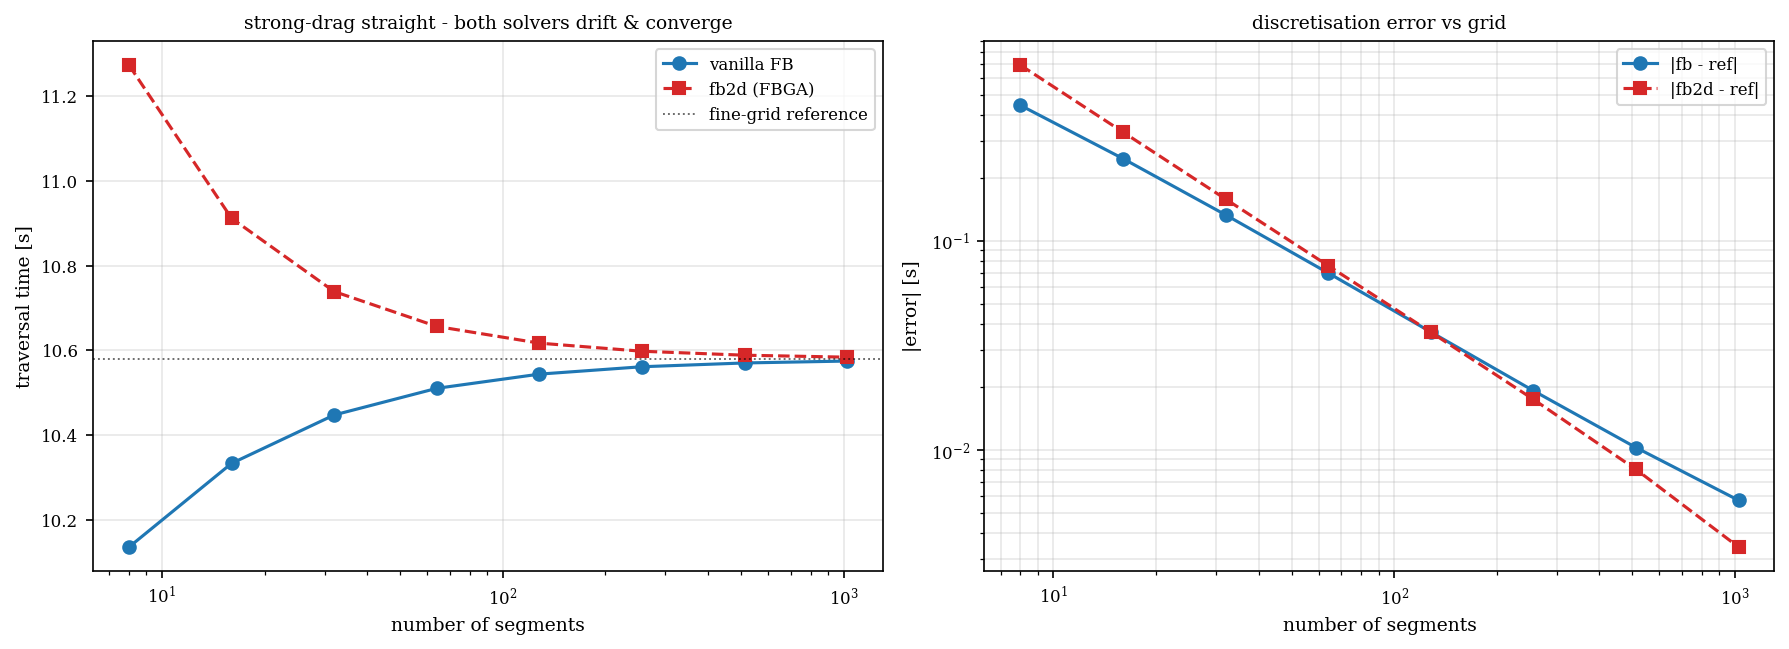

In [ ]:
# ===========================================================================
# Discretisation on a strong-drag straight (curvature removed, so curvature
# resampling is NOT the source of grid error): accelerate from a low speed
# under heavy aerodynamic drag and compare the traversal time from the vanilla
# FB solver and fb2d at several step sizes. FBGA's generic Fb2d samples the g-g
# callbacks per segment, so it is not grid-independent - both solvers drift and
# converge to the same limit as the grid refines (fb is actually closer at very
# coarse grids). This documents that the generic interface trades the paper's
# analytic exactness for arbitrary-envelope flexibility.
# ===========================================================================
from OptiLine.KinematicProfs import calc_vel_profile, calc_vel_profile_fb2d, calc_t_profile

L      = 400.0     # straight length [m]
DRAG_S = 5.0       # strong aerodynamic drag coefficient [kg/m]
M_S    = 1000.0
V0     = 5.0       # entry speed [m/s]
VCAP   = 120.0     # high v_max so drag (not the cap) governs the accel run
ggv_s  = np.array([[0., 12., 12.], [200., 12., 12.]])   # constant 12/12 g-g
axm_s  = np.array([[0., 12.], [200., 12.]])

def _traverse_time(nseg, solver):
    ds  = L / nseg
    el  = np.full(nseg, ds)
    kap = np.zeros(nseg + 1)                              # open, straight: len(kappa) = len(el)+1
    if solver == 'fb':
        vx = calc_vel_profile(ggv=ggv_s, ax_max_machines=axm_s, v_max=VCAP, kappa=kap,
                              el_lengths=el, closed=False, filt_window=None, dyn_model_exp=VEH['dyn_model_exp'],
                              drag_coeff=DRAG_S, m_veh=M_S, v_start=V0)
    else:
        vx = calc_vel_profile_fb2d(ggv=ggv_s, ax_max_machines=axm_s, v_max=VCAP, kappa=kap,
                                   el_lengths=el, closed=False, dyn_model_exp=VEH['dyn_model_exp'],
                                   drag_coeff=DRAG_S, m_veh=M_S, v_start=V0)
    return calc_t_profile(vx_profile=vx, el_lengths=el)[-1]

nsegs = [8, 16, 32, 64, 128, 256, 512, 1024]
t_fb  = [_traverse_time(n, 'fb')   for n in nsegs]
t_f2  = [_traverse_time(n, 'fb2d') for n in nsegs]
t_ref = _traverse_time(4000, 'fb2d')                     # fine-grid reference

print(f"Strong-drag straight (L={L:.0f} m, drag={DRAG_S}, v0={V0} m/s) - traversal time:")
print(f"  {'nseg':>6}{'ds[m]':>9}{'fb':>10}{'fb2d':>10}")
for n, a, b in zip(nsegs, t_fb, t_f2):
    print(f"  {n:>6}{L/n:>9.2f}{a:>10.4f}{b:>10.4f}")
print(f"  fine-grid reference (fb2d, 4000 seg) = {t_ref:.4f} s")

fig, (axT, axE) = plt.subplots(1, 2, figsize=(12, 4.4))
axT.plot(nsegs, t_fb, 'o-',  color='tab:blue', label='vanilla FB')
axT.plot(nsegs, t_f2, 's--', color='tab:red',  label='fb2d (FBGA)')
axT.axhline(t_ref, color='k', ls=':', lw=0.9, alpha=0.6, label='fine-grid reference')
axT.set_xscale('log'); axT.set_xlabel('number of segments'); axT.set_ylabel('traversal time [s]')
axT.set_title('strong-drag straight - both solvers drift & converge')
axT.grid(True, alpha=0.3); axT.legend(fontsize=8)
axE.plot(nsegs, np.abs(np.array(t_fb) - t_ref), 'o-',  color='tab:blue', label='|fb - ref|')
axE.plot(nsegs, np.abs(np.array(t_f2) - t_ref), 's--', color='tab:red',  label='|fb2d - ref|')
axE.set_xscale('log'); axE.set_yscale('log'); axE.set_xlabel('number of segments'); axE.set_ylabel('|error| [s]')
axE.set_title('discretisation error vs grid'); axE.grid(True, alpha=0.3, which='both'); axE.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'test4b_strong_drag_straight.png')); plt.show()
